## Local Jupyter setup

This notebook is configured for a local Windows Jupyter environment. It does not mount Google Drive. The default project location is `E:/SAM`. If your project folder is elsewhere, change `PROJECT_DIR` in the setup cell.

In [1]:
from pathlib import Path

PROJECT_DIR = Path(r"E:\SAM")
DATA_DIR = PROJECT_DIR / "data"
OUTPUT_DIR = PROJECT_DIR / "outputs"
CHECKPOINT_DIR = PROJECT_DIR / "checkpoints"
MANIFEST_DIR = PROJECT_DIR / "manifests"

for folder in (OUTPUT_DIR, CHECKPOINT_DIR, MANIFEST_DIR):
    folder.mkdir(parents=True, exist_ok=True)

print("Project directory:", PROJECT_DIR)
print("Project exists:", PROJECT_DIR.exists())
print("Data directory:", DATA_DIR)
print("Data directory exists:", DATA_DIR.exists())

Project directory: E:\SAM
Project exists: True
Data directory: E:\SAM\data
Data directory exists: True


In [2]:
# Local Jupyter Notebook: Google Drive mounting is not required.
# The project paths are configured in the setup cell below.

In [3]:
# Inspect class combinations

import pandas as pd
import json
from pathlib import Path

PROJECT_DIR = Path(r"E:\SAM")
DATA_DIR = PROJECT_DIR / "data"
MANIFEST_DIR = PROJECT_DIR / "manifests"

with open(MANIFEST_DIR / "dataset_manifest.json", "r") as f:
    records = json.load(f)

df = pd.read_csv(DATA_DIR / "train.csv")

# Build one record per image, keeping all classes associated with it.
classes_by_image = (
    df.groupby("ImageId")["ClassId"]
    .apply(lambda x: tuple(sorted(set(int(c) for c in x))))
    .to_dict()
)

manifest_df = pd.DataFrame(records)
manifest_df["class_ids"] = manifest_df["ImageId"].map(
    lambda image_id: classes_by_image.get(image_id, ())
)

# Summarise images by exact class combination.
manifest_df["class_combination"] = manifest_df["class_ids"].apply(
    lambda classes: (
        "+".join(map(str, classes)) if classes else "defect_free"
    )
)

print("IMAGE COUNTS BY CLASS COMBINATION")
print(
    manifest_df["class_combination"]
    .value_counts()
    .sort_index()
    .to_string()
)

print("\nTOTAL IMAGES:", len(manifest_df))
print(
    "DEFECT-PRESENT IMAGES:",
    int((manifest_df["class_combination"] != "defect_free").sum())
)
print(
    "DEFECT-FREE CANDIDATES:",
    int((manifest_df["class_combination"] == "defect_free").sum())
)


IMAGE COUNTS BY CLASS COMBINATION
class_combination
1               769
1+2              35
1+2+3             2
1+3              91
2               195
2+3              14
2+4               1
3              4759
3+4             284
4               516
defect_free    5902

TOTAL IMAGES: 12568
DEFECT-PRESENT IMAGES: 6666
DEFECT-FREE CANDIDATES: 5902


In [4]:
# Check split feasibility


import pandas as pd
import json
from pathlib import Path

PROJECT_DIR = Path(r"E:\SAM")
DATA_DIR = PROJECT_DIR / "data"
MANIFEST_DIR = PROJECT_DIR / "manifests"

with open(MANIFEST_DIR / "dataset_manifest.json", "r") as f:
    records = json.load(f)

df = pd.read_csv(DATA_DIR / "train.csv")
annotated_ids = set(df["ImageId"].unique())

all_ids = {r["ImageId"] for r in records}
defect_free_ids = all_ids - annotated_ids

# Count unique images containing each class, not CSV rows.
images_per_class = (
    df.groupby("ClassId")["ImageId"]
    .nunique()
    .sort_index()
)

print("TOTAL IMAGES:", len(all_ids))
print("DEFECT-PRESENT:", len(annotated_ids))
print("DEFECT-FREE CANDIDATES:", len(defect_free_ids))

print("\nUNIQUE IMAGES PER CLASS")
print(images_per_class.to_string())

test_size = 1200
dev_size = 200
s1_size = 50

remaining_after_test_dev = len(all_ids) - test_size - dev_size

print("\nPLANNED SPLIT FEASIBILITY")
print("Test set:", test_size)
print("Development set:", dev_size)
print("Images remaining for training pool:", remaining_after_test_dev)
print("Can fit all planned sizes:", remaining_after_test_dev >= s1_size)

print("\nMINIMUM CLASS COVERAGE CHECK")
print("Every class has at least 3 candidate images:",
      bool((images_per_class >= 3).all()))


TOTAL IMAGES: 12568
DEFECT-PRESENT: 6666
DEFECT-FREE CANDIDATES: 5902

UNIQUE IMAGES PER CLASS
ClassId
1     897
2     247
3    5150
4     801

PLANNED SPLIT FEASIBILITY
Test set: 1200
Development set: 200
Images remaining for training pool: 11168
Can fit all planned sizes: True

MINIMUM CLASS COVERAGE CHECK
Every class has at least 3 candidate images: True


In [5]:
# Generate the fixed-seed splits


import hashlib
import json
import pandas as pd
import numpy as np
from pathlib import Path
from sklearn.model_selection import train_test_split

SEED = 532
PROJECT_DIR = Path(r"E:\SAM")
DATA_DIR = PROJECT_DIR / "data"
MANIFEST_DIR = PROJECT_DIR / "manifests"
MANIFEST_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(DATA_DIR / "train.csv")
with open(MANIFEST_DIR / "dataset_manifest.json", "r") as f:
    records = json.load(f)

all_ids = sorted(r["ImageId"] for r in records)
classes_by_image = (
    df.groupby("ImageId")["ClassId"]
    .apply(lambda x: sorted(set(int(c) for c in x)))
    .to_dict()
)

# Each image has a four-element multi-label vector.
defect_ids = sorted(classes_by_image)
free_ids = sorted(set(all_ids) - set(defect_ids))

def vector(image_id):
    classes = set(classes_by_image.get(image_id, []))
    return [int(c in classes) for c in (1, 2, 3, 4)]

# Split defect-present and defect-free images separately.
# This guarantees the planned presence counts.
defect_train_dev, defect_test = train_test_split(
    defect_ids,
    test_size=1100,
    random_state=SEED,
    shuffle=True,
)

free_train_dev, free_test = train_test_split(
    free_ids,
    test_size=100,
    random_state=SEED,
    shuffle=True,
)

# Development: 100 defective + 100 defect-free.
defect_train, defect_dev = train_test_split(
    defect_train_dev,
    test_size=100,
    random_state=SEED + 1,
    shuffle=True,
)

free_train, free_dev = train_test_split(
    free_train_dev,
    test_size=100,
    random_state=SEED + 1,
    shuffle=True,
)

test_E = sorted(defect_test + free_test)
dev = sorted(defect_dev + free_dev)
train_pool = sorted(defect_train + free_train)

# Select S1 from defect-present training-pool images.
pool_defect_ids = [
    image_id for image_id in train_pool
    if image_id in classes_by_image
]

# Greedy seeded selection: each class must appear at least 3 times.
rng = np.random.default_rng(SEED)
candidates = list(pool_defect_ids)
rng.shuffle(candidates)

S1 = []
class_coverage = {c: 0 for c in (1, 2, 3, 4)}

# First ensure minimum coverage, then fill to 50.
while min(class_coverage.values()) < 3:
    eligible = [
        image_id for image_id in candidates
        if image_id not in S1
        and any(
            class_coverage[c] < 3
            for c in classes_by_image[image_id]
        )
    ]
    if not eligible:
        raise RuntimeError("Unable to satisfy S1 class coverage.")

    image_id = max(
        eligible,
        key=lambda item: (
            sum(
                class_coverage[c] < 3
                for c in classes_by_image[item]
            ),
            rng.random(),
        ),
    )
    S1.append(image_id)
    for c in classes_by_image[image_id]:
        class_coverage[c] += 1

remaining = [i for i in candidates if i not in S1]
S1.extend(remaining[:50 - len(S1)])

if len(S1) != 50:
    raise RuntimeError(f"S1 has {len(S1)} images, not 50.")

# H is a fixed, reproducible 10-image subset of defect-present test.
test_defect_ids = sorted(set(test_E) & set(defect_ids))
H = sorted(
    np.random.default_rng(SEED + 2)
    .choice(test_defect_ids, size=10, replace=False)
    .tolist()
)

splits = {
    "test_E": test_E,
    "dev": dev,
    "train_pool": train_pool,
    "S1": sorted(S1),
    "H": H,
}

# Validate required counts and disjointness.
assert len(test_E) == 1200
assert len(dev) == 200
assert len(train_pool) == 12568 - 1200 - 200
assert len(S1) == 50
assert len(H) == 10
assert set(test_E).isdisjoint(dev)
assert set(test_E).isdisjoint(train_pool)
assert set(dev).isdisjoint(train_pool)
assert set(S1).issubset(set(train_pool))
assert set(H).issubset(set(test_E))
assert set(H).issubset(set(defect_ids))

S1_coverage = {
    c: sum(c in classes_by_image[i] for i in S1)
    for c in (1, 2, 3, 4)
}
assert all(v >= 3 for v in S1_coverage.values()), S1_coverage

manifest = {
    "seed": SEED,
    "method": "image-level stratification by defect presence; fixed-seed S1 coverage selection",
    "splits": splits,
    "S1_unique_image_count_per_class": S1_coverage,
}

manifest_path = MANIFEST_DIR / "split_manifest.json"
with manifest_path.open("w", encoding="utf-8") as f:
    json.dump(manifest, f, indent=2)

manifest_hash = hashlib.sha256(manifest_path.read_bytes()).hexdigest()

print("Split manifest saved:", manifest_path)
print("SHA-256:", manifest_hash)
print("\nSplit counts:")
for name in splits:
    print(f"{name}: {len(splits[name])}")

print("\nS1 unique image counts per class:")
print(S1_coverage)
print("\nAll count, coverage, and disjointness assertions passed.")


Split manifest saved: E:\SAM\manifests\split_manifest.json
SHA-256: 7d01cb45f91e8c7112c38f3514abee87c2a24ac7dbccfb2c1dd5c7289df6f54a

Split counts:
test_E: 1200
dev: 200
train_pool: 11168
S1: 50
H: 10

S1 unique image counts per class:
{1: 5, 2: 3, 3: 43, 4: 8}

All count, coverage, and disjointness assertions passed.


In [6]:
# Audit the generated splits

import json
import pandas as pd
from pathlib import Path

PROJECT_DIR = Path(r"E:\SAM")
DATA_DIR = PROJECT_DIR / "data"
MANIFEST_DIR = PROJECT_DIR / "manifests"

with open(MANIFEST_DIR / "split_manifest.json", "r") as f:
    manifest = json.load(f)

df = pd.read_csv(DATA_DIR / "train.csv")
classes_by_image = (
    df.groupby("ImageId")["ClassId"]
    .apply(lambda x: set(int(c) for c in x))
    .to_dict()
)

all_ids = set(
    pd.read_json(
        MANIFEST_DIR / "dataset_manifest.json"
    )["ImageId"]
)

for split_name in ["test_E", "dev", "train_pool"]:
    ids = manifest["splits"][split_name]
    id_set = set(ids)

    defect_free = sum(i not in classes_by_image for i in ids)
    defect_present = len(ids) - defect_free

    print(f"\n{split_name}")
    print("Total:", len(ids))
    print("Defect-present:", defect_present)
    print("Defect-free:", defect_free)

    for class_id in (1, 2, 3, 4):
        count = sum(
            class_id in classes_by_image.get(i, set())
            for i in ids
        )
        print(f"  Class {class_id}: {count} images")

print("\nH subset")
h_ids = manifest["splits"]["H"]
print("Images:", len(h_ids))
print("All are in test_E:", set(h_ids).issubset(
    set(manifest["splits"]["test_E"])
))
print("All are defect-present:", all(
    i in classes_by_image for i in h_ids
))



test_E
Total: 1200
Defect-present: 1100
Defect-free: 100
  Class 1: 151 images
  Class 2: 36 images
  Class 3: 864 images
  Class 4: 134 images

dev
Total: 200
Defect-present: 100
Defect-free: 100
  Class 1: 17 images
  Class 2: 1 images
  Class 3: 77 images
  Class 4: 10 images

train_pool
Total: 11168
Defect-present: 5466
Defect-free: 5702
  Class 1: 729 images
  Class 2: 210 images
  Class 3: 4209 images
  Class 4: 657 images

H subset
Images: 10
All are in test_E: True
All are defect-present: True


In [7]:
import importlib.util

print("iterstrat installed:", importlib.util.find_spec("iterstrat") is not None)
print("scipy installed:", importlib.util.find_spec("scipy") is not None)
print("sklearn installed:", importlib.util.find_spec("sklearn") is not None)

iterstrat installed: False
scipy installed: True
sklearn installed: True


In [8]:
import numpy as np
import pandas as pd
import json
from pathlib import Path

SEED = 532

# Load annotations and current manifest
df = pd.read_csv(DATA_DIR / "train.csv")

with open(MANIFEST_DIR / "dataset_manifest.json", "r") as f:
    dataset_manifest = json.load(f)

all_ids = sorted(
    record["ImageId"] for record in dataset_manifest
) if isinstance(dataset_manifest, list) else sorted(
    record["ImageId"] for record in dataset_manifest["records"]
)

classes_by_image = (
    df.groupby("ImageId")["ClassId"]
      .apply(lambda x: sorted(set(int(c) for c in x)))
      .to_dict()
)

# Multi-label indicator matrix: one row per image, one column per class
X = np.zeros((len(all_ids), 4), dtype=np.int8)

for i, image_id in enumerate(all_ids):
    for class_id in classes_by_image.get(image_id, []):
        X[i, class_id - 1] = 1

is_defect = X.sum(axis=1) > 0

print("Images:", len(all_ids))
print("Defect-present:", int(is_defect.sum()))
print("Defect-free:", int((~is_defect).sum()))
print("Unique images per class:", X.sum(axis=0).tolist())
print("Class mix among defect-present images:")
for c in range(4):
    print(f"  Class {c + 1}: {int(X[is_defect, c].sum())}")

Images: 12568
Defect-present: 6666
Defect-free: 5902
Unique images per class: [897, 247, 5150, 801]
Class mix among defect-present images:
  Class 1: 897
  Class 2: 247
  Class 3: 5150
  Class 4: 801


In [9]:
#Generate improved splits
from sklearn.model_selection import train_test_split
import numpy as np

SEED = 532
rng = np.random.default_rng(SEED)

# X, all_ids, is_defect were prepared in the previous cell.
all_ids = np.asarray(all_ids)
defect_idx = np.flatnonzero(is_defect)
free_idx = np.flatnonzero(~is_defect)

# Stratify defect-free images separately: 100 test + 100 dev.
free_train_dev, free_test = train_test_split(
    free_idx,
    test_size=100,
    random_state=SEED,
)
free_train, free_dev = train_test_split(
    free_train_dev,
    test_size=100,
    random_state=SEED + 1,
)

# Greedy multi-label selection for defect-present images.
# Prioritizes classes that are rarer and currently underrepresented.
def greedy_select(indices, labels, n_select, target_counts, seed):
    rng_local = np.random.default_rng(seed)
    remaining = list(indices)
    selected = []
    counts = np.zeros(labels.shape[1], dtype=float)
    target = np.asarray(target_counts, dtype=float)

    while len(selected) < n_select:
        best_score = -np.inf
        best_idx = None

        for idx in remaining:
            row = labels[idx].astype(float)
            unmet = np.maximum(target - counts, 0)
            score = np.sum(
                row * unmet / np.maximum(target, 1)
                / np.maximum(labels[indices].sum(axis=0), 1)
            )
            score += rng_local.random() * 1e-9

            if score > best_score:
                best_score = score
                best_idx = idx

        selected.append(best_idx)
        counts += labels[best_idx]
        remaining.remove(best_idx)

    return np.array(selected), np.array(remaining)

# Allocate 1,100 defective images to test and 100 to dev.
defect_test, defect_remaining = greedy_select(
    defect_idx, X, 1100,
    target_counts=X[defect_idx].sum(axis=0) * (1100 / len(defect_idx)),
    seed=SEED,
)

defect_dev, defect_train = greedy_select(
    defect_remaining, X, 100,
    target_counts=X[defect_remaining].sum(axis=0) * (
        100 / len(defect_remaining)
    ),
    seed=SEED + 1,
)

test_idx = np.concatenate([defect_test, free_test])
dev_idx = np.concatenate([defect_dev, free_dev])
pool_idx = np.concatenate([defect_train, free_train])

# Convert indices to sorted image IDs.
test_E_new = sorted(all_ids[test_idx].tolist())
dev_new = sorted(all_ids[dev_idx].tolist())
train_pool_new = sorted(all_ids[pool_idx].tolist())

# Audit exact sizes and disjointness.
assert len(test_E_new) == 1200
assert len(dev_new) == 200
assert len(train_pool_new) == 11168
assert not (set(test_E_new) & set(dev_new))
assert not (set(test_E_new) & set(train_pool_new))
assert not (set(dev_new) & set(train_pool_new))

for name, ids in [
    ("test_E", test_E_new),
    ("dev", dev_new),
    ("train_pool", train_pool_new),
]:
    rows = [all_ids.tolist().index(i) for i in ids]
    print(f"\n{name}: {len(ids)} images")
    print("  Defect-present:", int(is_defect[rows].sum()))
    print("  Defect-free:", int((~is_defect[rows]).sum()))
    print("  Unique images per class:", X[rows].sum(axis=0).tolist())

print("\nSplit sizes and disjointness: PASS")
print("Existing manifest remains unchanged.")


test_E: 1200 images
  Defect-present: 1100
  Defect-free: 100
  Unique images per class: [174, 47, 995, 178]

dev: 200 images
  Defect-present: 100
  Defect-free: 100
  Unique images per class: [15, 4, 84, 16]

train_pool: 11168 images
  Defect-present: 5466
  Defect-free: 5702
  Unique images per class: [708, 196, 4071, 607]

Split sizes and disjointness: PASS
Existing manifest remains unchanged.


In [10]:
# Prepare defect-component counting
import cv2
import numpy as np
import pandas as pd
from collections import Counter

df = pd.read_csv(DATA_DIR / "train.csv")

# Group all class annotations by image.
rles_by_image = (
    df.groupby("ImageId")["EncodedPixels"]
      .apply(list)
      .to_dict()
)

def decode_rle(encoded_pixels, height=256, width=1600):
    values = np.asarray(
        [int(v) for v in encoded_pixels.split()],
        dtype=np.int64,
    )
    starts = values[0::2] - 1
    lengths = values[1::2]
    flat = np.zeros(height * width, dtype=np.uint8)

    for start, length in zip(starts, lengths):
        end = start + length
        if start < 0 or length <= 0 or end > flat.size:
            raise ValueError("Invalid RLE bounds")
        flat[start:end] = 1

    return flat.reshape((height, width), order="F")

def count_union_components(image_id):
    union_mask = np.zeros((256, 1600), dtype=np.uint8)

    for rle in rles_by_image[image_id]:
        union_mask |= decode_rle(rle)

    # 8-connected components; exclude background label 0.
    count, _, stats, _ = cv2.connectedComponentsWithStats(
        union_mask, connectivity=8
    )
    return count - 1

# Count components for every defect-present test image.
test_defect_ids = [
    image_id for image_id in test_E_new
    if image_id in rles_by_image
]

component_counts = {
    image_id: count_union_components(image_id)
    for image_id in test_defect_ids
}

print("Defect-present test images:", len(test_defect_ids))
print("Images with zero components:", sum(
    count == 0 for count in component_counts.values()
))
print("Component-count distribution:")
for count, frequency in sorted(Counter(component_counts.values()).items()):
    print(f"  {count} components: {frequency} images")


Defect-present test images: 1100
Images with zero components: 0
Component-count distribution:
  1 components: 305 images
  2 components: 243 images
  3 components: 177 images
  4 components: 122 images
  5 components: 68 images
  6 components: 44 images
  7 components: 44 images
  8 components: 30 images
  9 components: 25 images
  10 components: 11 images
  11 components: 12 images
  12 components: 2 images
  13 components: 5 images
  14 components: 5 images
  15 components: 2 images
  16 components: 2 images
  17 components: 1 images
  20 components: 1 images
  21 components: 1 images


In [11]:

import cv2
import numpy as np
import pandas as pd
import json
from pathlib import Path
from collections import Counter

PROJECT_DIR = Path(r"E:\SAM")
DATA_DIR = PROJECT_DIR / "data"
MANIFEST_DIR = PROJECT_DIR / "manifests"

df = pd.read_csv(DATA_DIR / "train.csv")

# Use the candidate split generated in the previous step.
# If those variables are unavailable, load the current saved split.
if "test_E_new" not in globals():
    raise RuntimeError(
        "test_E_new is not defined. Re-run the split-generation cell first."
    )

rles_by_image = (
    df.groupby("ImageId")["EncodedPixels"]
    .apply(list)
    .to_dict()
)

def decode_rle(encoded_pixels, height=256, width=1600):
    values = np.asarray(
        [int(v) for v in encoded_pixels.split()],
        dtype=np.int64
    )

    starts = values[0::2] - 1
    lengths = values[1::2]
    ends = starts + lengths

    flat = np.zeros(height * width, dtype=np.uint8)

    if np.any(starts < 0) or np.any(lengths <= 0) or np.any(ends > flat.size):
        raise ValueError("Invalid RLE run bounds")

    for start, end in zip(starts, ends):
        flat[start:end] = 1

    return flat.reshape((height, width), order="F")


def count_union_components(image_id):
    union_mask = np.zeros((256, 1600), dtype=np.uint8)

    for rle in rles_by_image[image_id]:
        union_mask |= decode_rle(rle)

    # Eight-connected components; label 0 is background.
    n_labels, labels, stats, centroids = (
        cv2.connectedComponentsWithStats(
            union_mask, connectivity=8
        )
    )

    return n_labels - 1


test_defect_ids = [
    image_id for image_id in test_E_new
    if image_id in rles_by_image
]

component_counts = {}

for i, image_id in enumerate(test_defect_ids, start=1):
    component_counts[image_id] = count_union_components(image_id)

    if i % 100 == 0:
        print(f"Processed {i}/{len(test_defect_ids)} images")

distribution = Counter(component_counts.values())

print("\nDefect-present test images:", len(test_defect_ids))
print("Images with zero components:", sum(
    count == 0 for count in component_counts.values()
))
print("\nComponent-count distribution:")
for count, frequency in sorted(distribution.items()):
    print(f"  {count} components: {frequency} images")

print("\nComponent counts calculated successfully.")


Processed 100/1100 images
Processed 200/1100 images
Processed 300/1100 images
Processed 400/1100 images
Processed 500/1100 images
Processed 600/1100 images
Processed 700/1100 images
Processed 800/1100 images
Processed 900/1100 images
Processed 1000/1100 images
Processed 1100/1100 images

Defect-present test images: 1100
Images with zero components: 0

Component-count distribution:
  1 components: 305 images
  2 components: 243 images
  3 components: 177 images
  4 components: 122 images
  5 components: 68 images
  6 components: 44 images
  7 components: 44 images
  8 components: 30 images
  9 components: 25 images
  10 components: 11 images
  11 components: 12 images
  12 components: 2 images
  13 components: 5 images
  14 components: 5 images
  15 components: 2 images
  16 components: 2 images
  17 components: 1 images
  20 components: 1 images
  21 components: 1 images

Component counts calculated successfully.


In [12]:
import numpy as np
from collections import Counter

SEED_H = 534
rng = np.random.default_rng(SEED_H)

def component_bin(count):
    if count <= 4:
        return str(count)
    return "5+"

# Group test images into component-count bins.
bins = {}
for image_id, count in component_counts.items():
    bins.setdefault(component_bin(count), []).append(image_id)

print("Available images per bin:")
for bin_name in ["1", "2", "3", "4", "5+"]:
    print(f"  {bin_name} components: {len(bins.get(bin_name, []))}")

# Select exactly two from each bin.
H_new = []
for bin_name in ["1", "2", "3", "4", "5+"]:
    candidates = sorted(bins[bin_name])
    selected = rng.choice(candidates, size=2, replace=False)
    H_new.extend(selected.tolist())

H_new = sorted(H_new)

# Validate selection.
assert len(H_new) == 10
assert len(set(H_new)) == 10
assert set(H_new).issubset(set(test_E_new))
assert all(image_id in component_counts for image_id in H_new)

print("\nSelected H:", len(H_new))
print("Selected component counts:")
for image_id in H_new:
    print(f"  {image_id}: {component_counts[image_id]} components")

print("\nH selection validation: PASS")

Available images per bin:
  1 components: 305
  2 components: 243
  3 components: 177
  4 components: 122
  5+ components: 253

Selected H: 10
Selected component counts:
  4f89dd316.jpg: 4 components
  6668e50d0.jpg: 4 components
  808c30930.jpg: 3 components
  8aa3af3da.jpg: 1 components
  bf9b21859.jpg: 1 components
  cd5b14850.jpg: 2 components
  e3b9a7b07.jpg: 2 components
  e5a59184b.jpg: 9 components
  f5dbf6137.jpg: 3 components
  fe2234ba6.jpg: 7 components

H selection validation: PASS


In [13]:

# Build S1 from the new training pool.
SEED_S1 = 533
rng = np.random.default_rng(SEED_S1)

pool_defect_ids = [
    image_id for image_id in train_pool_new
    if image_id in classes_by_image
]

# Shuffle candidates deterministically.
candidates = np.array(sorted(pool_defect_ids))
rng.shuffle(candidates)

S1_new = []
class_counts_s1 = Counter()

# First ensure every class is represented at least 3 times.
for class_id in [1, 2, 3, 4]:
    while class_counts_s1[class_id] < 3:
        eligible = [
            image_id for image_id in candidates
            if image_id not in S1_new
            and class_id in classes_by_image[image_id]
        ]
        if not eligible:
            raise RuntimeError(
                f"Cannot reach 3 images for class {class_id}"
            )

        chosen = eligible[0]
        S1_new.append(chosen)
        for c in classes_by_image[chosen]:
            class_counts_s1[c] += 1

# Fill the remaining slots with unique defect-present images.
for image_id in candidates:
    if len(S1_new) == 50:
        break
    if image_id not in S1_new:
        S1_new.append(image_id)
        for c in classes_by_image[image_id]:
            class_counts_s1[c] += 1

S1_new = sorted(S1_new)

# Final assertions.
assert len(S1_new) == 50
assert len(set(S1_new)) == 50
assert set(S1_new).issubset(set(train_pool_new))
assert not (set(S1_new) & set(test_E_new))
assert not (set(S1_new) & set(dev_new))
assert all(class_counts_s1[c] >= 3 for c in [1, 2, 3, 4])

print("S1 size:", len(S1_new))
print("S1 class coverage:", dict(sorted(class_counts_s1.items())))
print("S1 is defect-present:", all(i in classes_by_image for i in S1_new))
print("S1 disjoint from dev/test: PASS")


S1 size: 50
S1 class coverage: {1: 10, 2: 4, 3: 33, 4: 3}
S1 is defect-present: True
S1 disjoint from dev/test: PASS


In [14]:

import json
import hashlib
from pathlib import Path
from datetime import datetime, timezone

# Construct the proposed manifest.
new_manifest = {
    "seed": 532,
    "method": (
        "Greedy multi-label class-aware selection for defect-present "
        "images; seeded random split for defect-free images"
    ),
    "component_count_method": "8-connected components on union binary mask",
    "H_selection": {
        "seed": 534,
        "stratification_bins": ["1", "2", "3", "4", "5+"],
        "selection_per_bin": 2,
    },
    "S1_selection": {
        "seed": 533,
        "size": 50,
        "minimum_images_per_class": 3,
    },
    "splits": {
        "test_E": test_E_new,
        "dev": dev_new,
        "train_pool": train_pool_new,
        "S1": S1_new,
        "H": H_new,
    },
    "H_component_counts": {
        image_id: int(component_counts[image_id])
        for image_id in H_new
    },
}

# Validate the primary split sizes and disjointness.
test_set = set(test_E_new)
dev_set = set(dev_new)
pool_set = set(train_pool_new)
s1_set = set(S1_new)
h_set = set(H_new)

assert len(test_set) == 1200
assert len(dev_set) == 200
assert len(pool_set) == 11168
assert len(s1_set) == 50
assert len(h_set) == 10

assert not (test_set & dev_set)
assert not (test_set & pool_set)
assert not (dev_set & pool_set)
assert s1_set.issubset(pool_set)
assert h_set.issubset(test_set)
assert h_set.issubset(set(component_counts))

# Save separately so the old manifest remains untouched.
new_path = MANIFEST_DIR / "split_manifest_v2.json"
with open(new_path, "w") as f:
    json.dump(new_manifest, f, indent=2)

# Reload and validate the saved artifact.
with open(new_path, "r") as f:
    reloaded = json.load(f)

assert reloaded["splits"]["test_E"] == test_E_new
assert reloaded["splits"]["dev"] == dev_new
assert reloaded["splits"]["train_pool"] == train_pool_new
assert reloaded["splits"]["S1"] == S1_new
assert reloaded["splits"]["H"] == H_new

sha256 = hashlib.sha256(new_path.read_bytes()).hexdigest()

print("Saved:", new_path)
print("Manifest reload validation: PASS")
print("Split sizes: PASS")
print("Disjointness and subset checks: PASS")
print("SHA-256:", sha256)


Saved: E:\SAM\manifests\split_manifest_v2.json
Manifest reload validation: PASS
Split sizes: PASS
Disjointness and subset checks: PASS
SHA-256: 06819a37ed62823d0cc6972bfbc161fcfc2062b59bf630af8fd5121494f7b762


In [15]:
import json
import pandas as pd
from pathlib import Path

manifest_path = MANIFEST_DIR / "split_manifest_v2.json"

with open(manifest_path, "r") as f:
    manifest = json.load(f)

df = pd.read_csv(DATA_DIR / "train.csv")
classes_by_image = (
    df.groupby("ImageId")["ClassId"]
      .apply(lambda x: set(int(c) for c in x))
      .to_dict()
)

for split_name in ["test_E", "dev", "train_pool"]:
    ids = manifest["splits"][split_name]
    class_counts = {
        c: sum(c in classes_by_image.get(image_id, set()) for image_id in ids)
        for c in [1, 2, 3, 4]
    }
    defect_present = sum(image_id in classes_by_image for image_id in ids)

    print(f"\n{split_name}:")
    print("  Total images:", len(ids))
    print("  Defect-present:", defect_present)
    print("  Defect-free:", len(ids) - defect_present)
    print("  Class image counts:", class_counts)

print("\nH component counts:")
for image_id, count in manifest["H_component_counts"].items():
    print(f"  {image_id}: {count}")


test_E:
  Total images: 1200
  Defect-present: 1100
  Defect-free: 100
  Class image counts: {1: 174, 2: 47, 3: 995, 4: 178}

dev:
  Total images: 200
  Defect-present: 100
  Defect-free: 100
  Class image counts: {1: 15, 2: 4, 3: 84, 4: 16}

train_pool:
  Total images: 11168
  Defect-present: 5466
  Defect-free: 5702
  Class image counts: {1: 708, 2: 196, 3: 4071, 4: 607}

H component counts:
  4f89dd316.jpg: 4
  6668e50d0.jpg: 4
  808c30930.jpg: 3
  8aa3af3da.jpg: 1
  bf9b21859.jpg: 1
  cd5b14850.jpg: 2
  e3b9a7b07.jpg: 2
  e5a59184b.jpg: 9
  f5dbf6137.jpg: 3
  fe2234ba6.jpg: 7


In [16]:
import hashlib
from collections import defaultdict
from pathlib import Path

# Adjust this if your dataset uses a different image directory.
IMAGE_DIR = DATA_DIR / "train_images"

with open(MANIFEST_DIR / "split_manifest_v2.json", "r") as f:
    manifest = json.load(f)

split_names = ["test_E", "dev", "train_pool"]
hash_to_images = defaultdict(list)

for split_name in split_names:
    ids = manifest["splits"][split_name]
    for image_id in ids:
        image_path = IMAGE_DIR / image_id
        if not image_path.exists():
            raise FileNotFoundError(f"Missing image: {image_path}")

        digest = hashlib.sha256(image_path.read_bytes()).hexdigest()
        hash_to_images[digest].append((image_id, split_name))

cross_split_duplicates = [
    entries
    for entries in hash_to_images.values()
    if len({split for _, split in entries}) > 1
]

print("Images hashed:", sum(len(manifest["splits"][s]) for s in split_names))
print("Unique exact hashes:", len(hash_to_images))
print("Cross-split exact-duplicate groups:", len(cross_split_duplicates))

for group in cross_split_duplicates[:20]:
    print(group)

Images hashed: 12568
Unique exact hashes: 12568
Cross-split exact-duplicate groups: 0


In [17]:
import importlib.util

print("ImageHash installed:", importlib.util.find_spec("imagehash") is not None)
print("PIL installed:", importlib.util.find_spec("PIL") is not None)

ImageHash installed: False
PIL installed: True


In [18]:
from PIL import Image
from pathlib import Path
from collections import defaultdict
import numpy as np
import json

IMAGE_DIR = DATA_DIR / "train_images"

with open(MANIFEST_DIR / "split_manifest_v2.json", "r") as f:
    manifest = json.load(f)

split_names = ["test_E", "dev", "train_pool"]

def average_hash(image_path, hash_size=8):
    image = Image.open(image_path).convert("L")
    image = image.resize((hash_size, hash_size), Image.Resampling.LANCZOS)
    pixels = np.asarray(image, dtype=np.float32)
    return pixels > pixels.mean()

def hamming_distance(hash_a, hash_b):
    return int(np.count_nonzero(hash_a != hash_b))

# Calculate hashes for all images.
hashes = {}
image_split = {}

for split_name in split_names:
    for image_id in manifest["splits"][split_name]:
        image_path = IMAGE_DIR / image_id
        if not image_path.exists():
            raise FileNotFoundError(image_path)

        hashes[image_id] = average_hash(image_path)
        image_split[image_id] = split_name

print("Images hashed:", len(hashes))

# Compare only images from different splits.
# This simple all-pairs check may take some time.
cross_split_matches = []
ids = list(hashes)

for i, image_a in enumerate(ids):
    for image_b in ids[i + 1:]:
        if image_split[image_a] == image_split[image_b]:
            continue

        distance = hamming_distance(hashes[image_a], hashes[image_b])
        if distance <= 4:
            cross_split_matches.append((image_a, image_b, distance))

print("Cross-split candidate pairs (distance <= 4):", len(cross_split_matches))

for image_a, image_b, distance in cross_split_matches[:30]:
    print(
        f"{image_a} [{image_split[image_a]}] <-> "
        f"{image_b} [{image_split[image_b]}], distance={distance}"
    )

Images hashed: 12568
Cross-split candidate pairs (distance <= 4): 258113
0007a71bf.jpg [test_E] <-> 2930b4f52.jpg [dev], distance=4
0007a71bf.jpg [test_E] <-> 636700b91.jpg [dev], distance=2
0007a71bf.jpg [test_E] <-> 7232c2ceb.jpg [dev], distance=4
0007a71bf.jpg [test_E] <-> adeb12de3.jpg [dev], distance=4
0007a71bf.jpg [test_E] <-> b8031073a.jpg [dev], distance=4
0007a71bf.jpg [test_E] <-> 000a4bcdd.jpg [train_pool], distance=2
0007a71bf.jpg [test_E] <-> 002af848d.jpg [train_pool], distance=3
0007a71bf.jpg [test_E] <-> 00af2671f.jpg [train_pool], distance=1
0007a71bf.jpg [test_E] <-> 0218c0fcc.jpg [train_pool], distance=4
0007a71bf.jpg [test_E] <-> 0281aba7b.jpg [train_pool], distance=1
0007a71bf.jpg [test_E] <-> 02b906933.jpg [train_pool], distance=1
0007a71bf.jpg [test_E] <-> 03ba7286b.jpg [train_pool], distance=3
0007a71bf.jpg [test_E] <-> 04238d7e3.jpg [train_pool], distance=4
0007a71bf.jpg [test_E] <-> 044700866.jpg [train_pool], distance=4
0007a71bf.jpg [test_E] <-> 046282f58.j

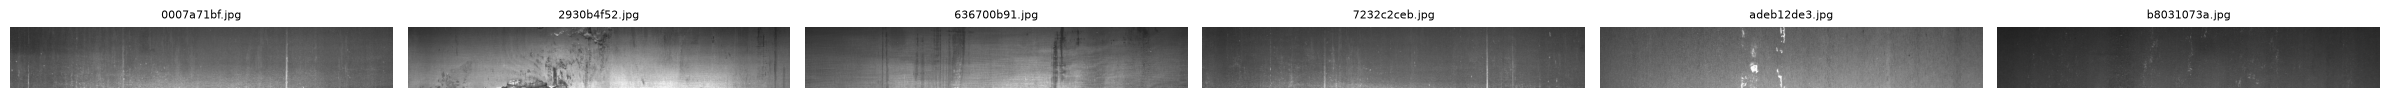

In [19]:
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path

IMAGE_DIR = DATA_DIR / "train_images"

reference_id = "0007a71bf.jpg"

candidate_ids = [
    image_b
    for image_a, image_b, distance in cross_split_matches
    if image_a == reference_id
][:5]

display_ids = [reference_id] + candidate_ids

fig, axes = plt.subplots(
    1, len(display_ids),
    figsize=(4 * len(display_ids), 3)
)

for ax, image_id in zip(axes, display_ids):
    image = Image.open(IMAGE_DIR / image_id).convert("RGB")
    ax.imshow(image)
    ax.set_title(image_id, fontsize=8)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [20]:

%pip install -q ImageHash

import imagehash
from PIL import Image

# Quick verification
sample_path = IMAGE_DIR / "0007a71bf.jpg"

with Image.open(sample_path) as img:
    sample_hash = imagehash.phash(img, hash_size=8)

print("ImageHash installed successfully")
print("Sample pHash:", sample_hash)
print("Hash bits:", len(sample_hash.hash.flatten()))


Note: you may need to restart the kernel to use updated packages.
ImageHash installed successfully
Sample pHash: 8039d67fd83d4926
Hash bits: 64


In [21]:

import json
import imagehash
import numpy as np
from PIL import Image
from pathlib import Path
from collections import Counter

IMAGE_DIR = DATA_DIR / "train_images"

with open(MANIFEST_DIR / "split_manifest_v2.json", "r") as f:
    manifest = json.load(f)

split_names = ["test_E", "dev", "train_pool"]

image_ids = []
split_labels = []
for split_name in split_names:
    for image_id in manifest["splits"][split_name]:
        image_ids.append(image_id)
        split_labels.append(split_name)

# Compute one 64-bit pHash per image.
hash_values = []
for i, image_id in enumerate(image_ids, start=1):
    with Image.open(IMAGE_DIR / image_id) as img:
        h = imagehash.phash(img.convert("RGB"), hash_size=8)
    hash_values.append(np.asarray(h.hash, dtype=np.uint8).reshape(-1))

    if i % 1000 == 0:
        print(f"Hashed {i}/{len(image_ids)} images")

hash_matrix = np.stack(hash_values)
split_labels = np.asarray(split_labels)

# Pack each 64-bit hash into a single integer.
packed_hashes = np.packbits(hash_matrix, axis=1)
hash_ints = np.array([
    int.from_bytes(row.tobytes(), byteorder="big")
    for row in packed_hashes
], dtype=object)

# Compare across splits. Count candidates without retaining every pair.
candidate_pairs = []
for i in range(len(image_ids)):
    for j in range(i + 1, len(image_ids)):
        if split_labels[i] == split_labels[j]:
            continue

        distance = (hash_ints[i] ^ hash_ints[j]).bit_count()
        if distance <= 4:
            candidate_pairs.append(
                (image_ids[i], split_labels[i],
                 image_ids[j], split_labels[j], distance)
            )

print("\nImages hashed:", len(image_ids))
print("Cross-split candidate pairs (pHash distance <= 4):",
      len(candidate_pairs))

for pair in candidate_pairs[:30]:
    print(pair)


Hashed 1000/12568 images
Hashed 2000/12568 images
Hashed 3000/12568 images
Hashed 4000/12568 images
Hashed 5000/12568 images
Hashed 6000/12568 images
Hashed 7000/12568 images
Hashed 8000/12568 images
Hashed 9000/12568 images
Hashed 10000/12568 images
Hashed 11000/12568 images
Hashed 12000/12568 images

Images hashed: 12568
Cross-split candidate pairs (pHash distance <= 4): 31
('0141c9bf3.jpg', np.str_('test_E'), '72e49c314.jpg', np.str_('train_pool'), 4)
('048d14d3f.jpg', np.str_('test_E'), '7c8a469a4.jpg', np.str_('train_pool'), 0)
('112942aed.jpg', np.str_('test_E'), 'f00c6d4b2.jpg', np.str_('dev'), 4)
('210e0e803.jpg', np.str_('test_E'), 'a82acacf2.jpg', np.str_('train_pool'), 4)
('36689bafd.jpg', np.str_('test_E'), '25b4312a0.jpg', np.str_('train_pool'), 4)
('3de8f5d88.jpg', np.str_('test_E'), 'a5aa4829b.jpg', np.str_('train_pool'), 0)
('5f33ded37.jpg', np.str_('test_E'), 'be9bac1d9.jpg', np.str_('train_pool'), 4)
('64b61a1b3.jpg', np.str_('test_E'), '27b3f78bc.jpg', np.str_('train

Zero-distance pairs: 7


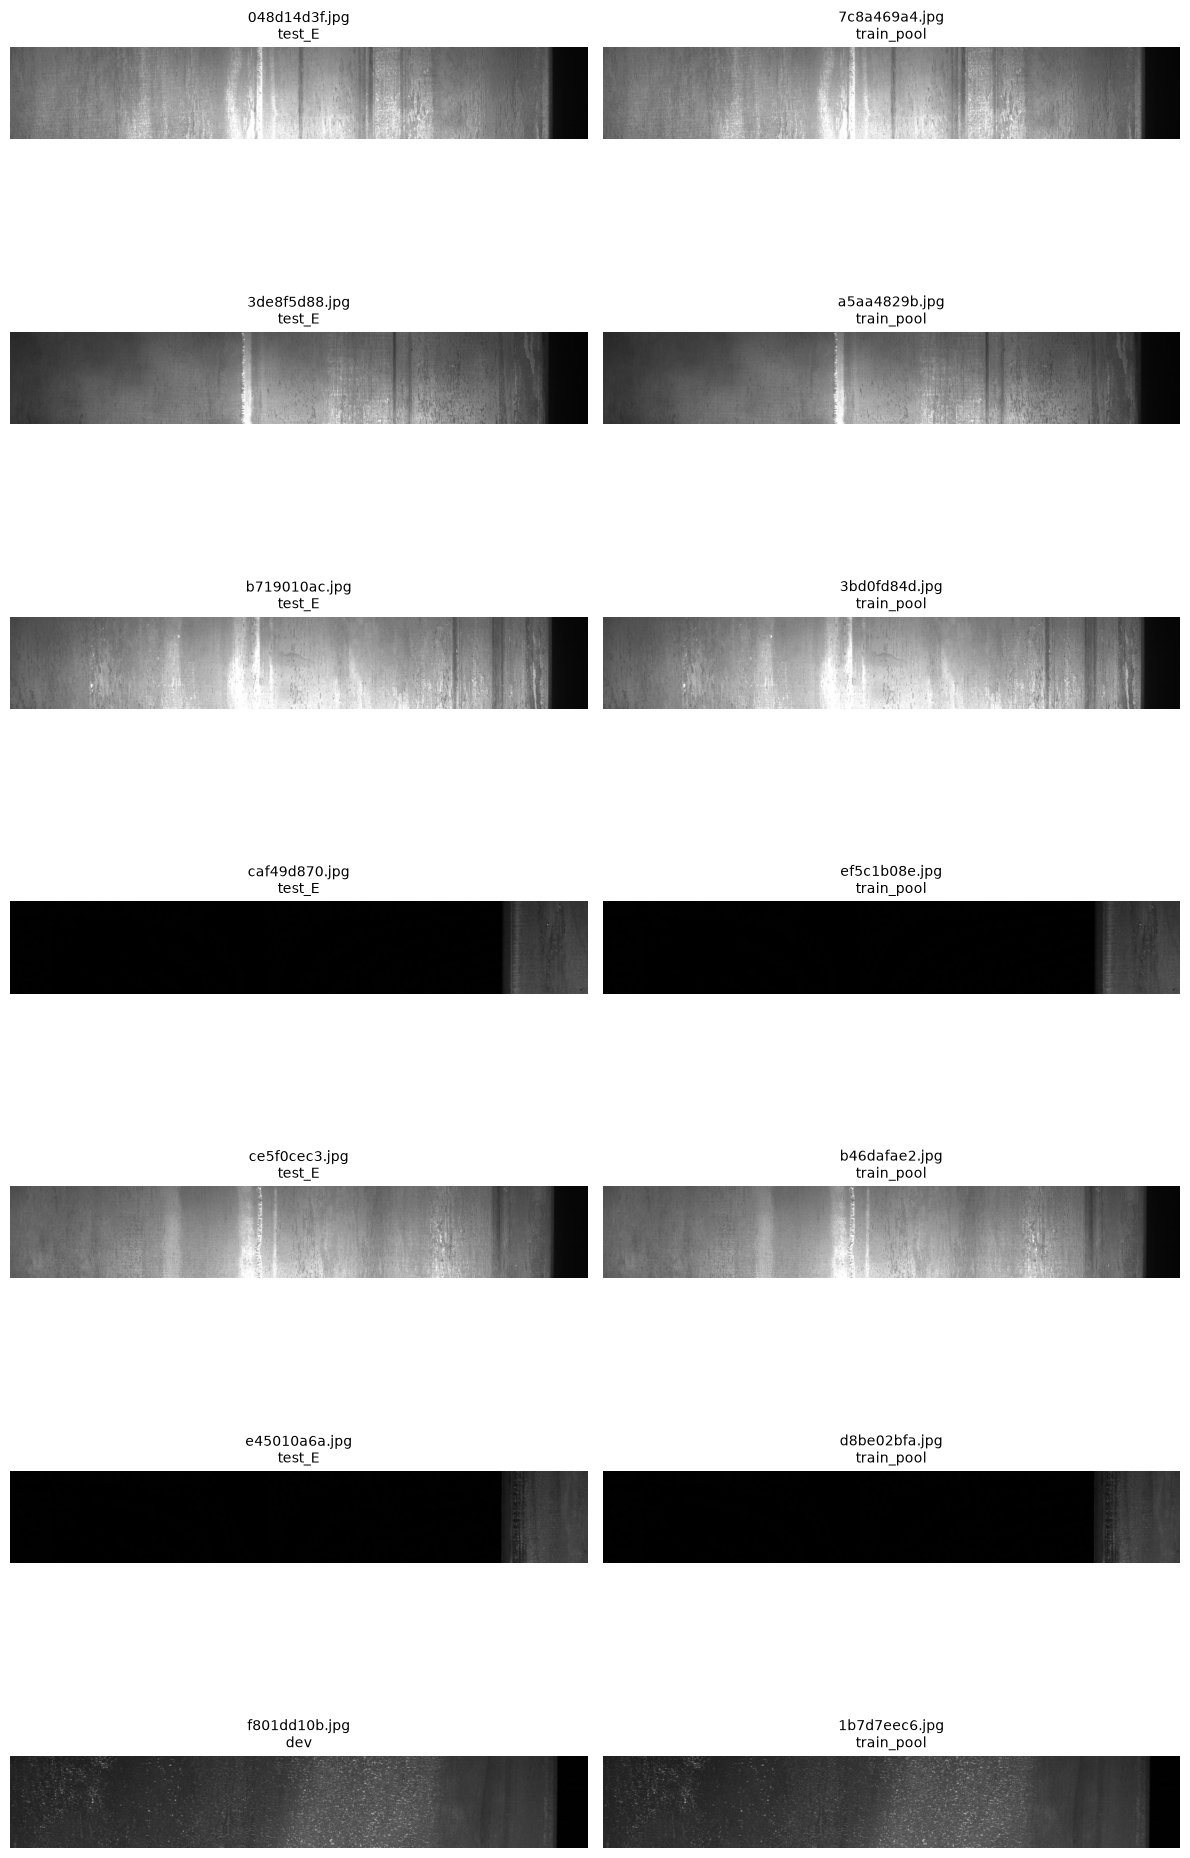

In [22]:

import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path

IMAGE_DIR = DATA_DIR / "train_images"

# Exact perceptual-hash matches from the screening results.
zero_distance_pairs = [
    pair for pair in candidate_pairs if pair[4] == 0
]

print("Zero-distance pairs:", len(zero_distance_pairs))

fig, axes = plt.subplots(
    len(zero_distance_pairs), 2,
    figsize=(12, 3 * len(zero_distance_pairs))
)

if len(zero_distance_pairs) == 1:
    axes = [axes]

for row, pair in enumerate(zero_distance_pairs):
    image_a, split_a, image_b, split_b, distance = pair

    for col, (image_id, split_name) in enumerate([
        (image_a, split_a),
        (image_b, split_b),
    ]):
        with Image.open(IMAGE_DIR / image_id) as img:
            axes[row][col].imshow(img.convert("RGB"))

        axes[row][col].set_title(
            f"{image_id}\n{split_name}", fontsize=10
        )
        axes[row][col].axis("off")

plt.tight_layout()
plt.show()


In [23]:
from PIL import Image, ImageChops
import numpy as np

pairs_to_check = [
    ("048d14d3f.jpg", "7c8a469a4.jpg"),
    ("3de8f5d88.jpg", "a5aa4829b.jpg"),
    ("b719010ac.jpg", "3bd0fd84d.jpg"),
    ("caf49d870.jpg", "ef5c1b08e.jpg"),
    ("ce5f0cec3.jpg", "b46dafae2.jpg"),
    ("e45010a6a.jpg", "d8be02bfa.jpg"),
    ("f801dd10b.jpg", "1b7d7eec6.jpg"),
]

for a, b in pairs_to_check:
    with Image.open(IMAGE_DIR / a) as im_a:
        arr_a = np.asarray(im_a.convert("RGB"))
    with Image.open(IMAGE_DIR / b) as im_b:
        arr_b = np.asarray(im_b.convert("RGB"))

    same_shape = arr_a.shape == arr_b.shape
    if same_shape:
        mae = float(np.abs(
            arr_a.astype(np.int16) - arr_b.astype(np.int16)
        ).mean())
        exact_pixels = bool(np.array_equal(arr_a, arr_b))
    else:
        mae = None
        exact_pixels = False

    print(
        f"{a} <-> {b}: "
        f"same_shape={same_shape}, "
        f"exact_pixels={exact_pixels}, "
        f"mean_abs_difference={mae}"
    )

048d14d3f.jpg <-> 7c8a469a4.jpg: same_shape=True, exact_pixels=False, mean_abs_difference=0.00654052734375
3de8f5d88.jpg <-> a5aa4829b.jpg: same_shape=True, exact_pixels=False, mean_abs_difference=0.00390869140625
b719010ac.jpg <-> 3bd0fd84d.jpg: same_shape=True, exact_pixels=False, mean_abs_difference=0.0046533203125
caf49d870.jpg <-> ef5c1b08e.jpg: same_shape=True, exact_pixels=False, mean_abs_difference=0.0021630859375
ce5f0cec3.jpg <-> b46dafae2.jpg: same_shape=True, exact_pixels=False, mean_abs_difference=0.0050927734375
e45010a6a.jpg <-> d8be02bfa.jpg: same_shape=True, exact_pixels=False, mean_abs_difference=0.002001953125
f801dd10b.jpg <-> 1b7d7eec6.jpg: same_shape=True, exact_pixels=False, mean_abs_difference=0.004091796875


In [24]:
import numpy as np
from PIL import Image

for a, b in pairs_to_check:
    with Image.open(IMAGE_DIR / a) as im_a:
        arr_a = np.asarray(im_a.convert("RGB"), dtype=np.int16)
    with Image.open(IMAGE_DIR / b) as im_b:
        arr_b = np.asarray(im_b.convert("RGB"), dtype=np.int16)

    diff = np.abs(arr_a - arr_b)

    print(f"\n{a} <-> {b}")
    print("  Shape:", arr_a.shape, arr_b.shape)
    print("  Exact pixel match:", np.array_equal(arr_a, arr_b))
    print("  Mean absolute difference:", float(diff.mean()))
    print("  Maximum absolute difference:", int(diff.max()))
    print("  Different channel values:", int(np.count_nonzero(diff)))
    print("  Total channel values:", diff.size)


048d14d3f.jpg <-> 7c8a469a4.jpg
  Shape: (256, 1600, 3) (256, 1600, 3)
  Exact pixel match: False
  Mean absolute difference: 0.00654052734375
  Maximum absolute difference: 6
  Different channel values: 5658
  Total channel values: 1228800

3de8f5d88.jpg <-> a5aa4829b.jpg
  Shape: (256, 1600, 3) (256, 1600, 3)
  Exact pixel match: False
  Mean absolute difference: 0.00390869140625
  Maximum absolute difference: 4
  Different channel values: 4158
  Total channel values: 1228800

b719010ac.jpg <-> 3bd0fd84d.jpg
  Shape: (256, 1600, 3) (256, 1600, 3)
  Exact pixel match: False
  Mean absolute difference: 0.0046533203125
  Maximum absolute difference: 5
  Different channel values: 4401
  Total channel values: 1228800

caf49d870.jpg <-> ef5c1b08e.jpg
  Shape: (256, 1600, 3) (256, 1600, 3)
  Exact pixel match: False
  Mean absolute difference: 0.0021630859375
  Maximum absolute difference: 1
  Different channel values: 2658
  Total channel values: 1228800

ce5f0cec3.jpg <-> b46dafae2.jpg
 

In [25]:
import hashlib
from pathlib import Path
from PIL import Image

for a, b in pairs_to_check:
    path_a = IMAGE_DIR / a
    path_b = IMAGE_DIR / b

    def file_sha256(path):
        return hashlib.sha256(path.read_bytes()).hexdigest()

    with Image.open(path_a) as im_a:
        meta_a = {
            "format": im_a.format,
            "mode": im_a.mode,
            "size": im_a.size,
            "info": dict(im_a.info),
        }

    with Image.open(path_b) as im_b:
        meta_b = {
            "format": im_b.format,
            "mode": im_b.mode,
            "size": im_b.size,
            "info": dict(im_b.info),
        }

    print(f"\n{a} <-> {b}")
    print("  SHA-256 equal:", file_sha256(path_a) == file_sha256(path_b))
    print("  Format:", meta_a["format"], "/", meta_b["format"])
    print("  Mode:", meta_a["mode"], "/", meta_b["mode"])
    print("  Dimensions:", meta_a["size"], "/", meta_b["size"])
    print("  Metadata equal:", meta_a["info"] == meta_b["info"])


048d14d3f.jpg <-> 7c8a469a4.jpg
  SHA-256 equal: False
  Format: JPEG / JPEG
  Mode: RGB / RGB
  Dimensions: (1600, 256) / (1600, 256)
  Metadata equal: True

3de8f5d88.jpg <-> a5aa4829b.jpg
  SHA-256 equal: False
  Format: JPEG / JPEG
  Mode: RGB / RGB
  Dimensions: (1600, 256) / (1600, 256)
  Metadata equal: True

b719010ac.jpg <-> 3bd0fd84d.jpg
  SHA-256 equal: False
  Format: JPEG / JPEG
  Mode: RGB / RGB
  Dimensions: (1600, 256) / (1600, 256)
  Metadata equal: True

caf49d870.jpg <-> ef5c1b08e.jpg
  SHA-256 equal: False
  Format: JPEG / JPEG
  Mode: RGB / RGB
  Dimensions: (1600, 256) / (1600, 256)
  Metadata equal: True

ce5f0cec3.jpg <-> b46dafae2.jpg
  SHA-256 equal: False
  Format: JPEG / JPEG
  Mode: RGB / RGB
  Dimensions: (1600, 256) / (1600, 256)
  Metadata equal: True

e45010a6a.jpg <-> d8be02bfa.jpg
  SHA-256 equal: False
  Format: JPEG / JPEG
  Mode: RGB / RGB
  Dimensions: (1600, 256) / (1600, 256)
  Metadata equal: True

f801dd10b.jpg <-> 1b7d7eec6.jpg
  SHA-256 equ

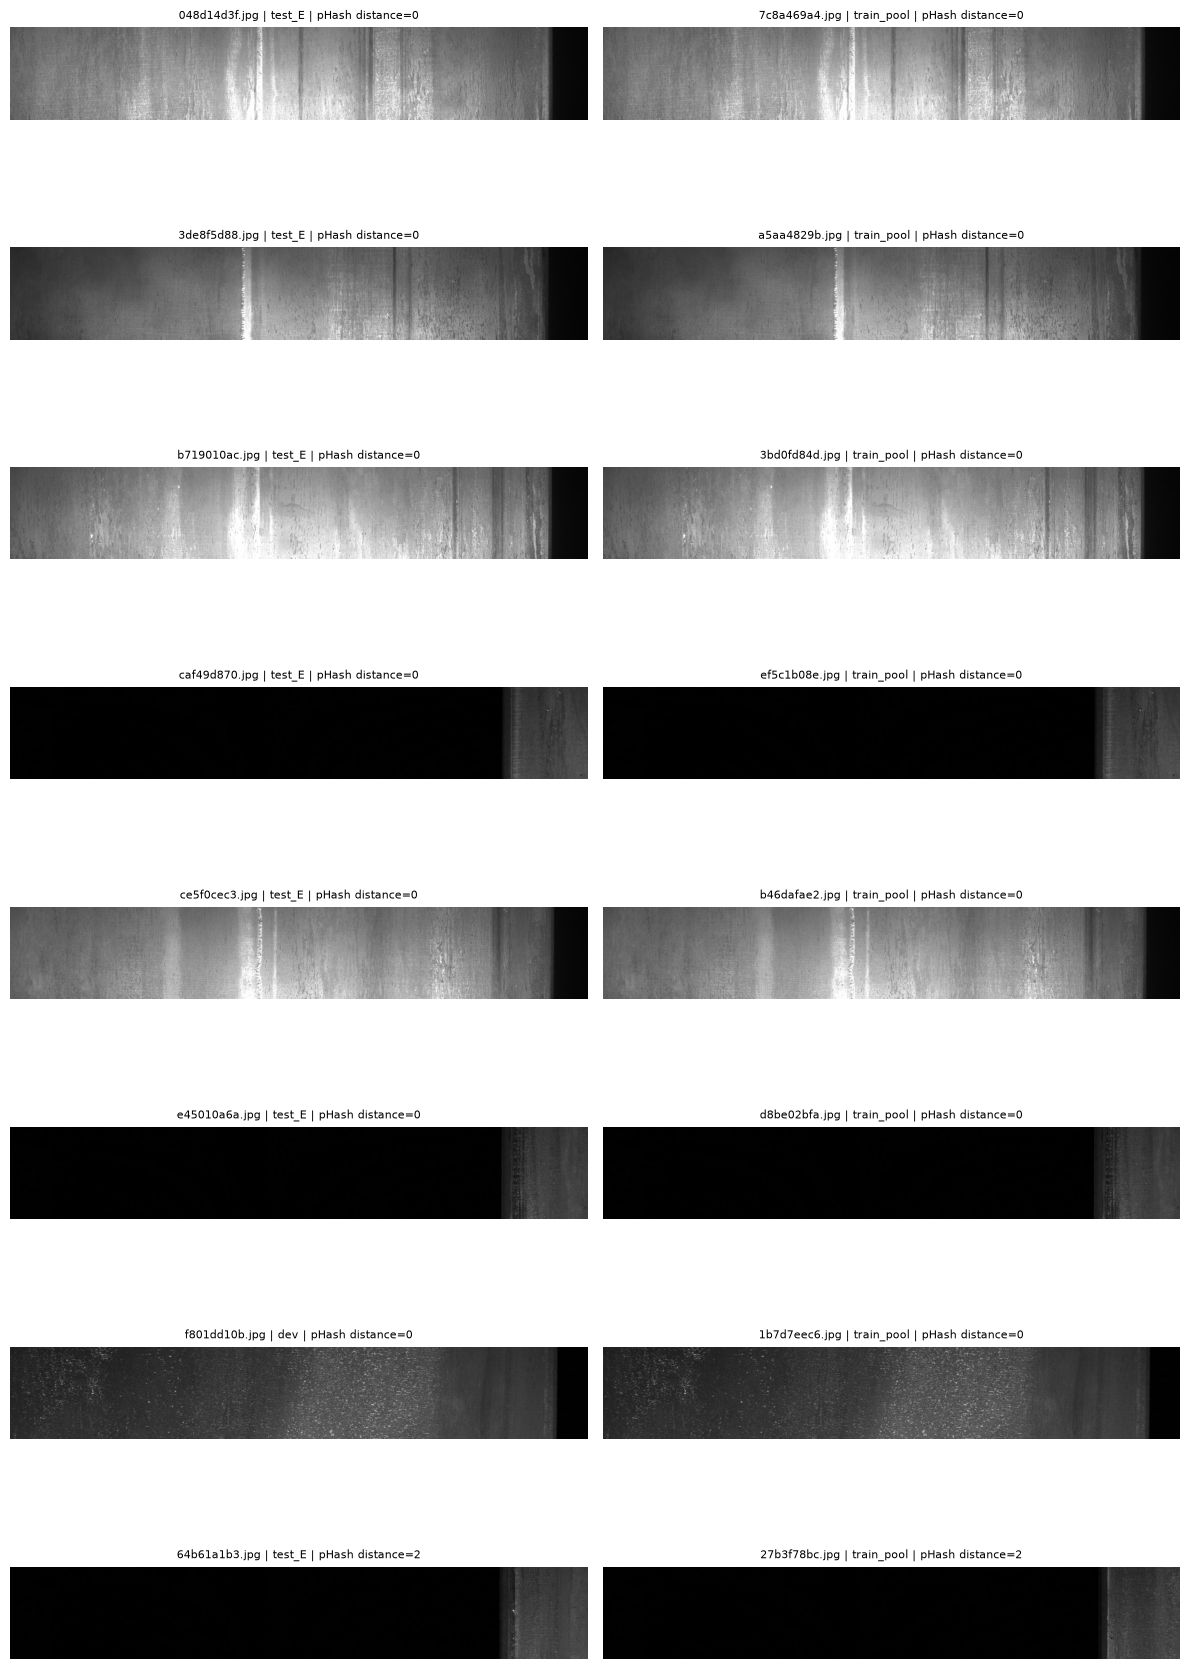

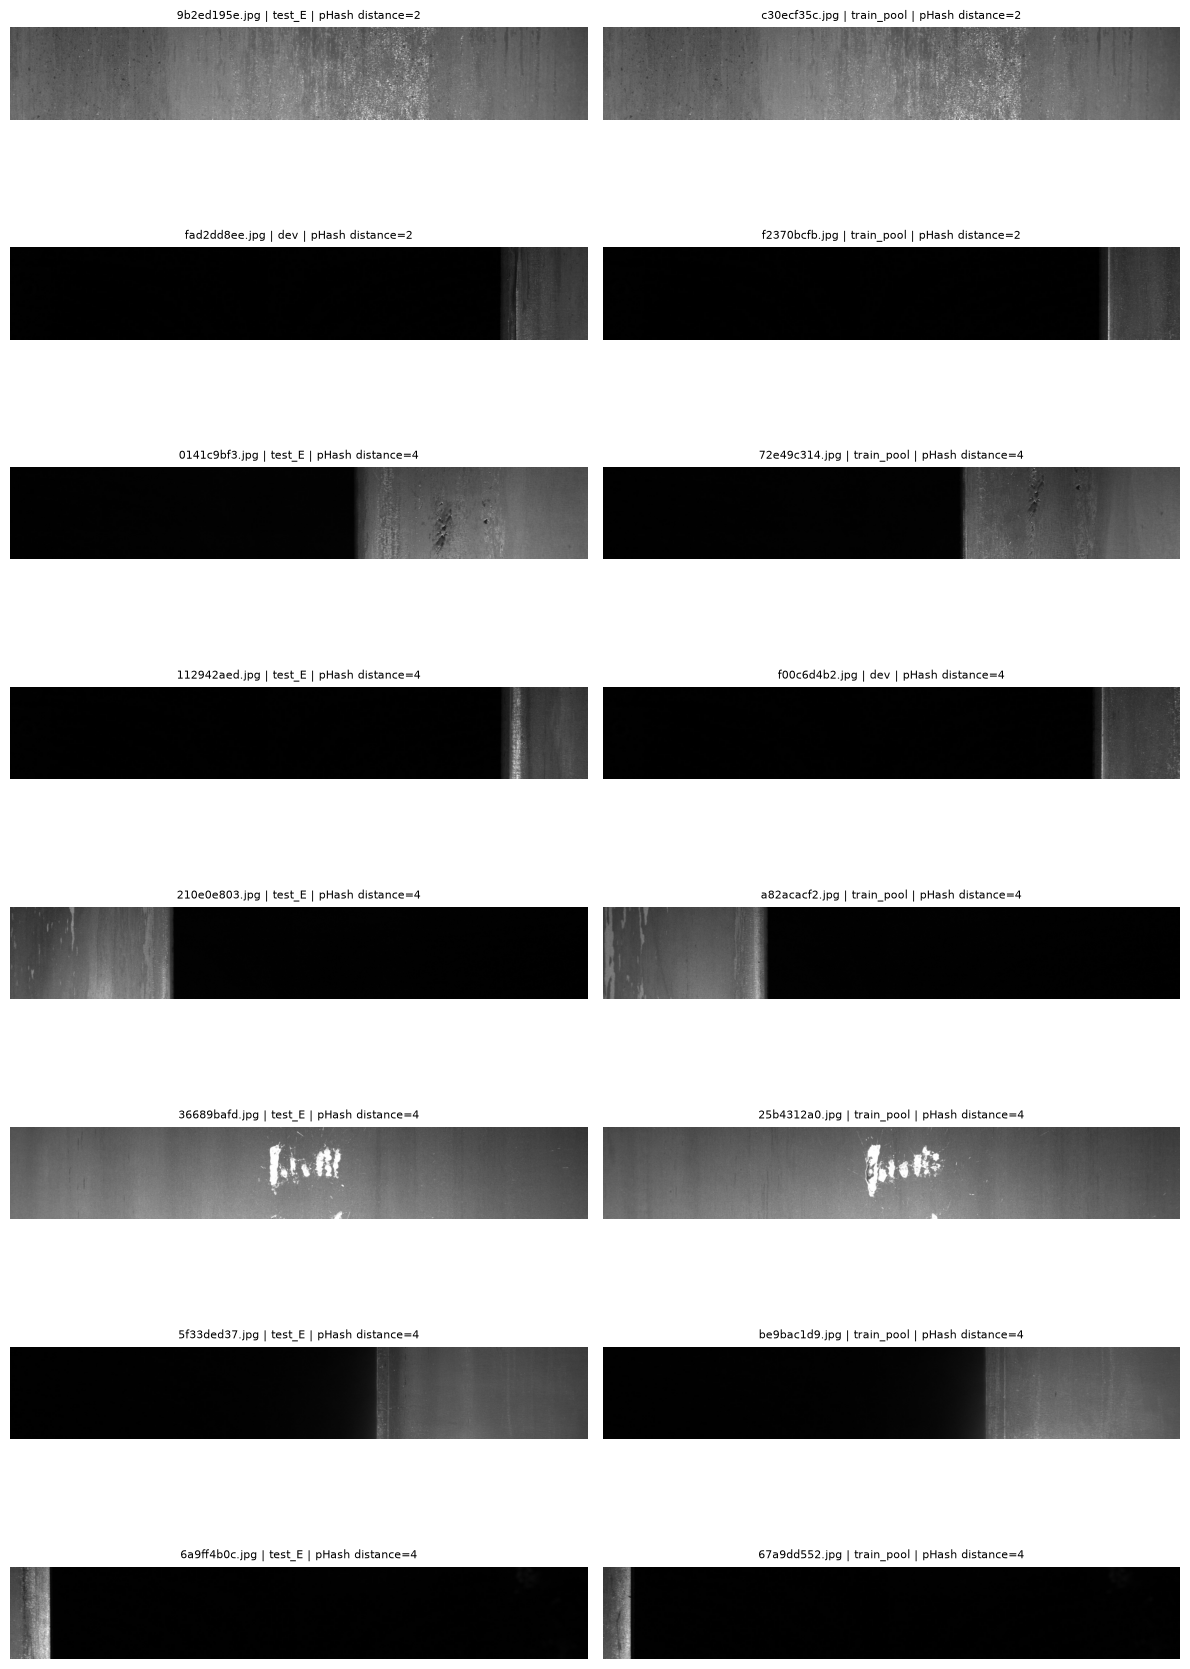

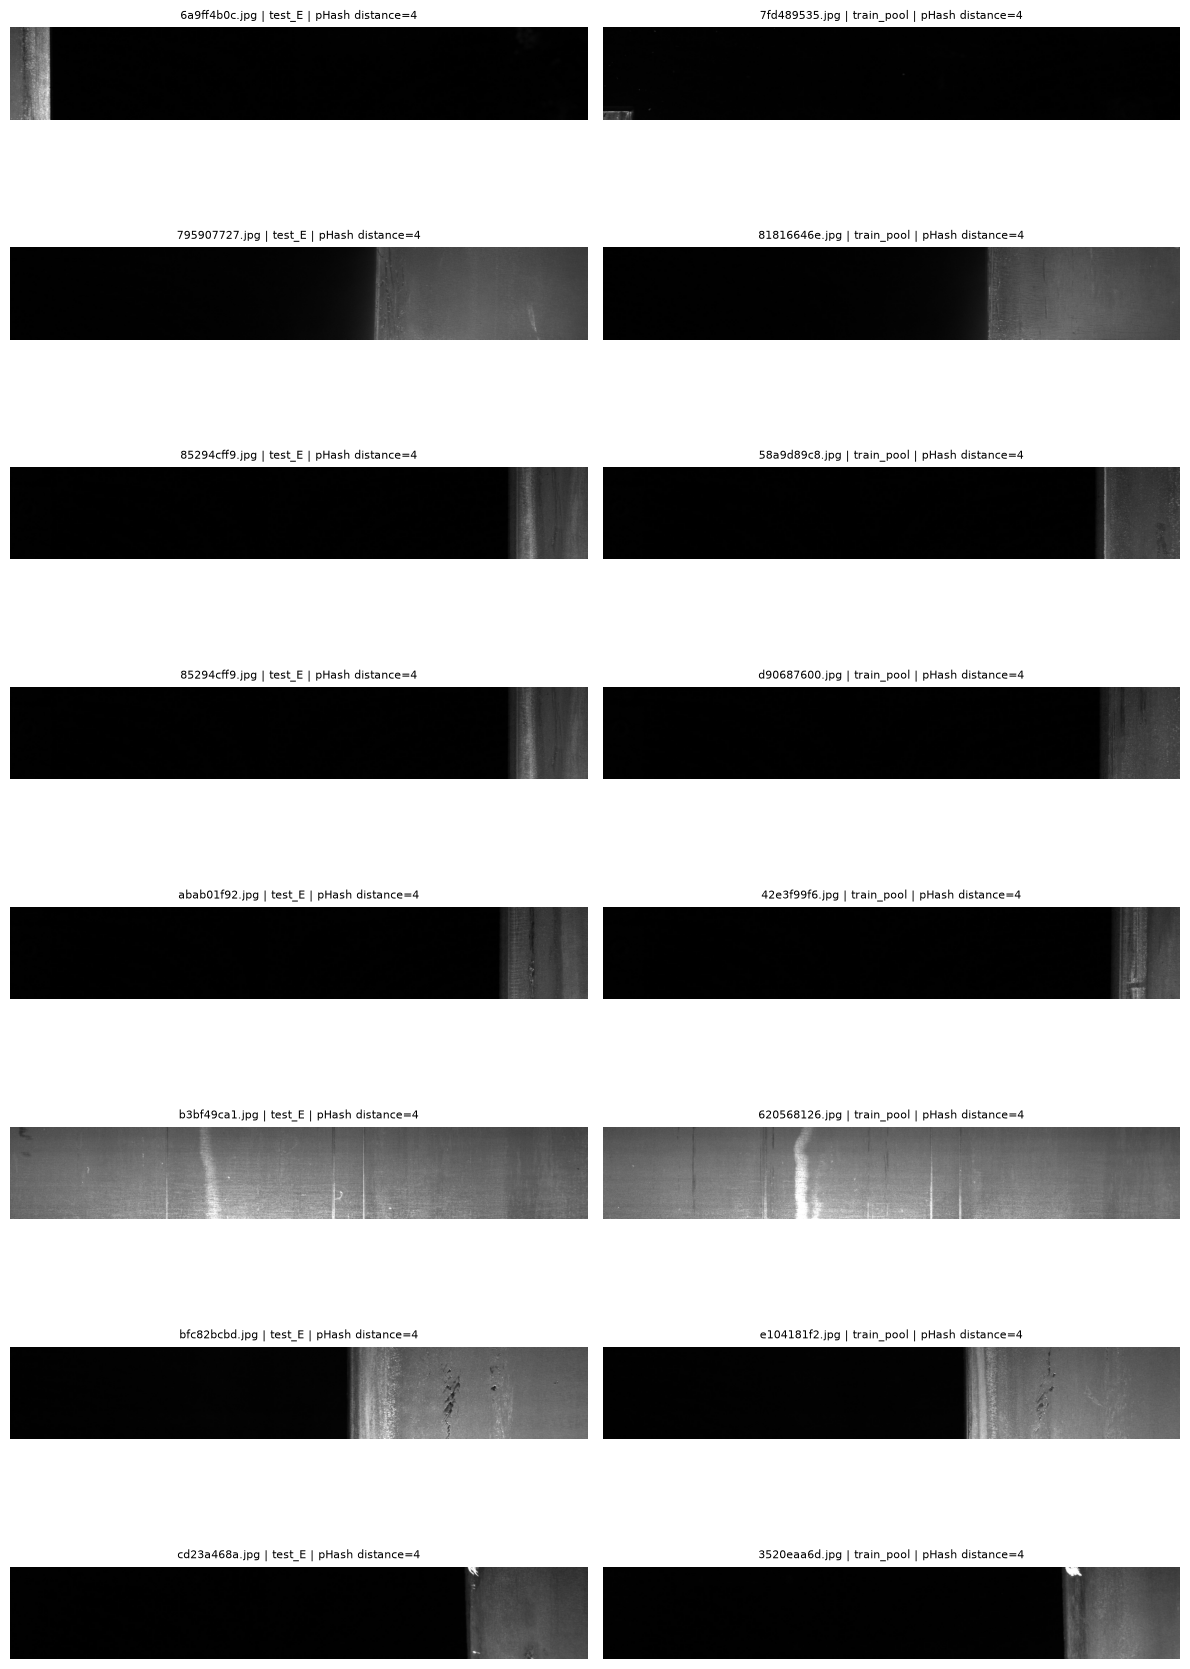

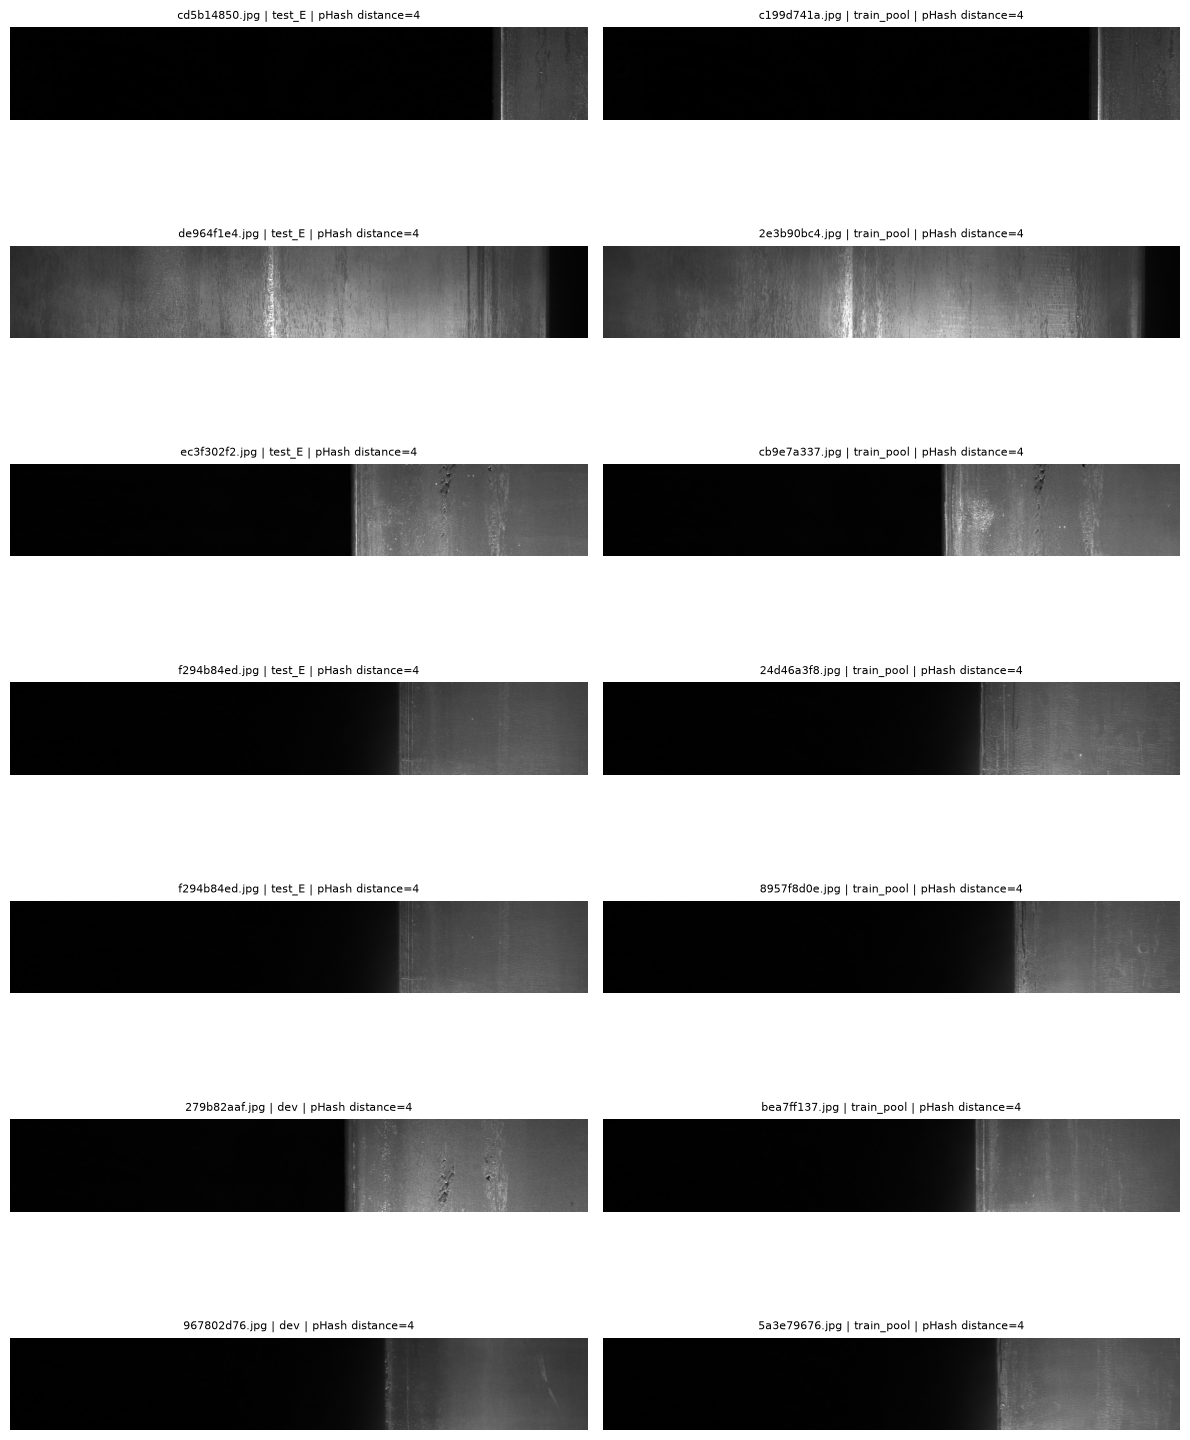

In [26]:
import matplotlib.pyplot as plt
from PIL import Image

IMAGE_DIR = DATA_DIR / "train_images"

# Sort strongest matches first.
sorted_candidates = sorted(candidate_pairs, key=lambda p: p[4])

for start in range(0, len(sorted_candidates), 8):
    batch = sorted_candidates[start:start + 8]

    fig, axes = plt.subplots(
        len(batch), 2,
        figsize=(12, 2.3 * len(batch))
    )

    if len(batch) == 1:
        axes = np.array([axes])

    for row, pair in enumerate(batch):
        image_a, split_a, image_b, split_b, distance = pair

        for col, (image_id, split_name) in enumerate([
            (image_a, split_a),
            (image_b, split_b),
        ]):
            with Image.open(IMAGE_DIR / image_id) as img:
                axes[row][col].imshow(img.convert("RGB"))

            axes[row][col].set_title(
                f"{image_id} | {split_name} | pHash distance={distance}",
                fontsize=8
            )
            axes[row][col].axis("off")

    plt.tight_layout()
    plt.show()

In [27]:
import pandas as pd
import json

df = pd.read_csv(DATA_DIR / "train.csv")

classes_by_image = (
    df.groupby("ImageId")["ClassId"]
      .apply(lambda x: sorted(set(int(c) for c in x)))
      .to_dict()
)

zero_distance_pairs = [
    pair for pair in candidate_pairs if pair[4] == 0
]

for image_a, split_a, image_b, split_b, distance in zero_distance_pairs:
    classes_a = classes_by_image.get(image_a, [])
    classes_b = classes_by_image.get(image_b, [])

    print(f"\n{image_a} [{split_a}]")
    print(f"  Classes: {classes_a or 'defect-free'}")
    print(f"{image_b} [{split_b}]")
    print(f"  Classes: {classes_b or 'defect-free'}")
    print("  Same class set:", classes_a == classes_b)


048d14d3f.jpg [test_E]
  Classes: [3]
7c8a469a4.jpg [train_pool]
  Classes: [3]
  Same class set: True

3de8f5d88.jpg [test_E]
  Classes: [3]
a5aa4829b.jpg [train_pool]
  Classes: [3]
  Same class set: True

b719010ac.jpg [test_E]
  Classes: [3]
3bd0fd84d.jpg [train_pool]
  Classes: [3]
  Same class set: True

caf49d870.jpg [test_E]
  Classes: [1, 2]
ef5c1b08e.jpg [train_pool]
  Classes: [1]
  Same class set: False

ce5f0cec3.jpg [test_E]
  Classes: [3]
b46dafae2.jpg [train_pool]
  Classes: [3]
  Same class set: True

e45010a6a.jpg [test_E]
  Classes: [3]
d8be02bfa.jpg [train_pool]
  Classes: defect-free
  Same class set: False

f801dd10b.jpg [dev]
  Classes: defect-free
1b7d7eec6.jpg [train_pool]
  Classes: defect-free
  Same class set: True


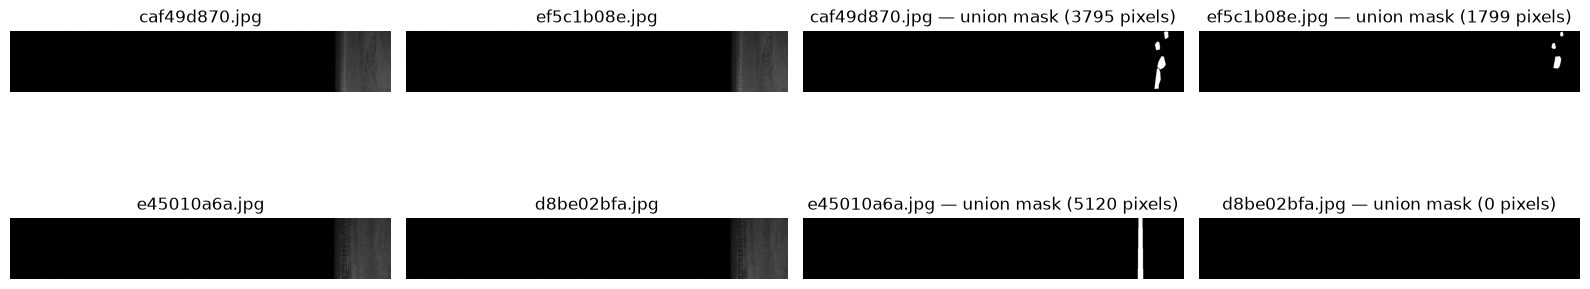

In [28]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

mismatch_pairs = [
    ("caf49d870.jpg", "ef5c1b08e.jpg"),
    ("e45010a6a.jpg", "d8be02bfa.jpg"),
]

def union_mask_for_image(image_id):
    mask = np.zeros((256, 1600), dtype=np.uint8)
    for rle in rles_by_image.get(image_id, []):
        mask |= decode_rle(rle)
    return mask

fig, axes = plt.subplots(2, 4, figsize=(16, 5))

for row, (image_a, image_b) in enumerate(mismatch_pairs):
    for col, image_id in enumerate([image_a, image_b]):
        with Image.open(IMAGE_DIR / image_id) as img:
            axes[row, col].imshow(img.convert("RGB"))
        axes[row, col].set_title(image_id)
        axes[row, col].axis("off")

        mask = union_mask_for_image(image_id)
        axes[row, col + 2].imshow(mask, cmap="gray", vmin=0, vmax=1)
        axes[row, col + 2].set_title(
            f"{image_id} — union mask ({int(mask.sum())} pixels)"
        )
        axes[row, col + 2].axis("off")

plt.tight_layout()
plt.show()

In [29]:
import csv
import json
from pathlib import Path

audit_path = MANIFEST_DIR / "perceptual_duplicate_audit.csv"

with open(audit_path, "w", newline="") as f:
    writer = csv.writer(f)
    writer.writerow([
        "image_a",
        "split_a",
        "image_b",
        "split_b",
        "phash_distance",
        "review_status",
        "notes",
    ])

    for image_a, split_a, image_b, split_b, distance in sorted(
        candidate_pairs, key=lambda p: p[4]
    ):
        writer.writerow([
            image_a,
            str(split_a),
            image_b,
            str(split_b),
            int(distance),
            "pending_manual_review",
            "",
        ])

print("Audit record saved:", audit_path)
print("Candidate pairs recorded:", len(candidate_pairs))
print("Zero-distance pairs:", sum(p[4] == 0 for p in candidate_pairs))

Audit record saved: E:\SAM\manifests\perceptual_duplicate_audit.csv
Candidate pairs recorded: 31
Zero-distance pairs: 7


In [30]:
import pandas as pd
import json

audit_path = MANIFEST_DIR / "perceptual_duplicate_audit.csv"
audit = pd.read_csv(audit_path)
df = pd.read_csv(DATA_DIR / "train.csv")

classes_by_image = (
    df.groupby("ImageId")["ClassId"]
      .apply(lambda x: sorted(set(int(c) for c in x)))
      .to_dict()
)

train_candidates = audit[
    ((audit["split_a"] == "test_E") & (audit["split_b"] == "train_pool")) |
    ((audit["split_a"] == "train_pool") & (audit["split_b"] == "test_E")) |
    ((audit["split_a"] == "dev") & (audit["split_b"] == "train_pool")) |
    ((audit["split_a"] == "train_pool") & (audit["split_b"] == "dev"))
].copy()

def get_train_image(row):
    if row["split_a"] == "train_pool":
        return row["image_a"]
    return row["image_b"]

def get_reference_image(row):
    if row["split_a"] == "train_pool":
        return row["image_b"]
    return row["image_a"]

train_candidates["reference_image"] = train_candidates.apply(
    get_reference_image, axis=1
)
train_candidates["train_image"] = train_candidates.apply(
    get_train_image, axis=1
)
train_candidates["reference_classes"] = train_candidates[
    "reference_image"
].map(lambda x: classes_by_image.get(x, []))
train_candidates["train_classes"] = train_candidates[
    "train_image"
].map(lambda x: classes_by_image.get(x, []))

print("Cross-split candidate pairs:", len(train_candidates))
display(
    train_candidates[
        [
            "reference_image",
            "train_image",
            "phash_distance",
            "reference_classes",
            "train_classes",
        ]
    ].sort_values(["phash_distance", "reference_image"])
)

Cross-split candidate pairs: 30


,reference_image,train_image,phash_distance,reference_classes,train_classes
0,048d14d3f.jpg,7c8a469a4.jpg,0,[3],[3]
1,3de8f5d88.jpg,a5aa4829b.jpg,0,[3],[3]
2,b719010ac.jpg,3bd0fd84d.jpg,0,[3],[3]
3,caf49d870.jpg,ef5c1b08e.jpg,0,"[1, 2]",[1]
4,ce5f0cec3.jpg,b46dafae2.jpg,0,[3],[3]
5,e45010a6a.jpg,d8be02bfa.jpg,0,[3],[]
6,f801dd10b.jpg,1b7d7eec6.jpg,0,[],[]
7,64b61a1b3.jpg,27b3f78bc.jpg,2,[3],[]
8,9b2ed195e.jpg,c30ecf35c.jpg,2,[],[]
9,fad2dd8ee.jpg,f2370bcfb.jpg,2,"[2, 3]",[]


In [31]:

import pandas as pd
import json

audit_path = MANIFEST_DIR / "perceptual_duplicate_audit.csv"
audit = pd.read_csv(audit_path)

# Restrict to test/train or dev/train pairs with pHash distance 0.
zero = audit[
    (audit["phash_distance"] == 0) &
    (
        ((audit["split_a"] == "test_E") & (audit["split_b"] == "train_pool")) |
        ((audit["split_a"] == "train_pool") & (audit["split_b"] == "test_E")) |
        ((audit["split_a"] == "dev") & (audit["split_b"] == "train_pool")) |
        ((audit["split_a"] == "train_pool") & (audit["split_b"] == "dev"))
    )
].copy()

proposed_exclusions = set()

for _, row in zero.iterrows():
    if row["split_a"] == "train_pool":
        proposed_exclusions.add(row["image_a"])
    elif row["split_b"] == "train_pool":
        proposed_exclusions.add(row["image_b"])

proposed_exclusions = sorted(proposed_exclusions)

print("Proposed training exclusions:", len(proposed_exclusions))
for image_id in proposed_exclusions:
    print(" ", image_id)

print("\nNo images removed; manifest unchanged.")


Proposed training exclusions: 7
  1b7d7eec6.jpg
  3bd0fd84d.jpg
  7c8a469a4.jpg
  a5aa4829b.jpg
  b46dafae2.jpg
  d8be02bfa.jpg
  ef5c1b08e.jpg

No images removed; manifest unchanged.


In [32]:
import json
from pathlib import Path

exclusion_proposal = {
    "status": "pending_manual_confirmation",
    "rule": (
        "Flag cross-split training images paired with test_E or dev "
        "images at pHash Hamming distance 0."
    ),
    "reason": (
        "Identical pHash plus visual similarity; candidates require "
        "manual confirmation before exclusion."
    ),
    "proposed_training_exclusions": proposed_exclusions,
    "pairs": [
        {
            "reference_image": (
                row["image_b"]
                if row["split_a"] == "train_pool"
                else row["image_a"]
            ),
            "training_image": (
                row["image_a"]
                if row["split_a"] == "train_pool"
                else row["image_b"]
            ),
            "phash_distance": int(row["phash_distance"]),
        }
        for _, row in zero.iterrows()
    ],
}

proposal_path = MANIFEST_DIR / "proposed_training_exclusions.json"

with open(proposal_path, "w") as f:
    json.dump(exclusion_proposal, f, indent=2)

print("Proposal saved:", proposal_path)
print("Proposed exclusions:", len(proposed_exclusions))
print("Status:", exclusion_proposal["status"])
print("Original split manifest unchanged.")

Proposal saved: E:\SAM\manifests\proposed_training_exclusions.json
Proposed exclusions: 7
Status: pending_manual_confirmation
Original split manifest unchanged.


In [33]:

import json
from pathlib import Path

with open(MANIFEST_DIR / "split_manifest_v2.json", "r") as f:
    manifest = json.load(f)

with open(MANIFEST_DIR / "proposed_training_exclusions.json", "r") as f:
    proposal = json.load(f)

test_set = set(manifest["splits"]["test_E"])
dev_set = set(manifest["splits"]["dev"])
pool_set = set(manifest["splits"]["train_pool"])
excluded = set(proposal["proposed_training_exclusions"])

print("All proposed images in train_pool:", excluded.issubset(pool_set))
print("Any overlap with test_E:", bool(excluded & test_set))
print("Any overlap with dev:", bool(excluded & dev_set))
print("Original train_pool size:", len(pool_set))
print("Effective pool size if exclusions applied:", len(pool_set - excluded))

assert excluded.issubset(pool_set)
assert not (excluded & test_set)
assert not (excluded & dev_set)

print("\nExclusion membership validation: PASS")
print("Manifest unchanged.")


All proposed images in train_pool: True
Any overlap with test_E: False
Any overlap with dev: False
Original train_pool size: 11168
Effective pool size if exclusions applied: 11161

Exclusion membership validation: PASS
Manifest unchanged.


In [34]:

import json
import hashlib
from pathlib import Path

effective_pool = sorted(pool_set - excluded)

effective_pool_record = {
    "status": "provisional_pending_manual_confirmation",
    "source_manifest": "split_manifest_v2.json",
    "exclusion_proposal": "proposed_training_exclusions.json",
    "original_train_pool_size": len(pool_set),
    "proposed_exclusions_count": len(excluded),
    "effective_train_pool_size": len(effective_pool),
    "excluded_images": sorted(excluded),
    "effective_train_pool": effective_pool,
    "test_E_unchanged": True,
    "dev_unchanged": True,
}

effective_path = MANIFEST_DIR / "effective_train_pool_provisional.json"

with open(effective_path, "w") as f:
    json.dump(effective_pool_record, f, indent=2)

digest = hashlib.sha256(effective_path.read_bytes()).hexdigest()

print("Saved:", effective_path)
print("Effective pool size:", len(effective_pool))
print("SHA-256:", digest)
print("Status:", effective_pool_record["status"])
print("Original split manifest unchanged.")


Saved: E:\SAM\manifests\effective_train_pool_provisional.json
Effective pool size: 11161
SHA-256: c8f3d7b484345ed31b26c307994252e31746cb83a3b9f4a5a93c02aa78303ded
Status: provisional_pending_manual_confirmation
Original split manifest unchanged.


In [35]:

import pandas as pd
import numpy as np

df = pd.read_csv(DATA_DIR / "train.csv")

def encode_rle(mask):
    pixels = mask.flatten(order="F")
    padded = np.concatenate([[0], pixels, [0]])
    changes = np.where(padded[1:] != padded[:-1])[0] + 1
    changes[1::2] -= changes[::2]
    return " ".join(map(str, changes))

def decode_rle_checked(encoded_pixels, height=256, width=1600):
    values = np.asarray(
        [int(v) for v in encoded_pixels.split()],
        dtype=np.int64,
    )

    if len(values) == 0 or len(values) % 2 != 0:
        raise ValueError("Empty or odd-length RLE")

    starts = values[0::2] - 1
    lengths = values[1::2]
    ends = starts + lengths

    if np.any(starts < 0) or np.any(lengths <= 0):
        raise ValueError("Invalid RLE start or length")
    if np.any(ends > height * width):
        raise ValueError("RLE exceeds image bounds")

    flat = np.zeros(height * width, dtype=np.uint8)
    for start, end in zip(starts, ends):
        flat[start:end] = 1

    return flat.reshape((height, width), order="F")

errors = []
for i, row in enumerate(df.itertuples(index=False), start=1):
    try:
        decoded = decode_rle_checked(row.EncodedPixels)
        encoded_again = encode_rle(decoded)

        if encoded_again != row.EncodedPixels:
            errors.append((i, row.ImageId, row.ClassId, "round-trip mismatch"))
    except Exception as exc:
        errors.append((i, row.ImageId, row.ClassId, str(exc)))

    if i % 500 == 0:
        print(f"Checked {i}/{len(df)} records")

print("\nTotal records:", len(df))
print("Failed records:", len(errors))
print("RLE round-trip audit:", "PASS" if not errors else "FAIL")

for error in errors[:20]:
    print(error)


Checked 500/7095 records
Checked 1000/7095 records
Checked 1500/7095 records
Checked 2000/7095 records
Checked 2500/7095 records
Checked 3000/7095 records
Checked 3500/7095 records
Checked 4000/7095 records
Checked 4500/7095 records
Checked 5000/7095 records
Checked 5500/7095 records
Checked 6000/7095 records
Checked 6500/7095 records
Checked 7000/7095 records

Total records: 7095
Failed records: 0
RLE round-trip audit: PASS


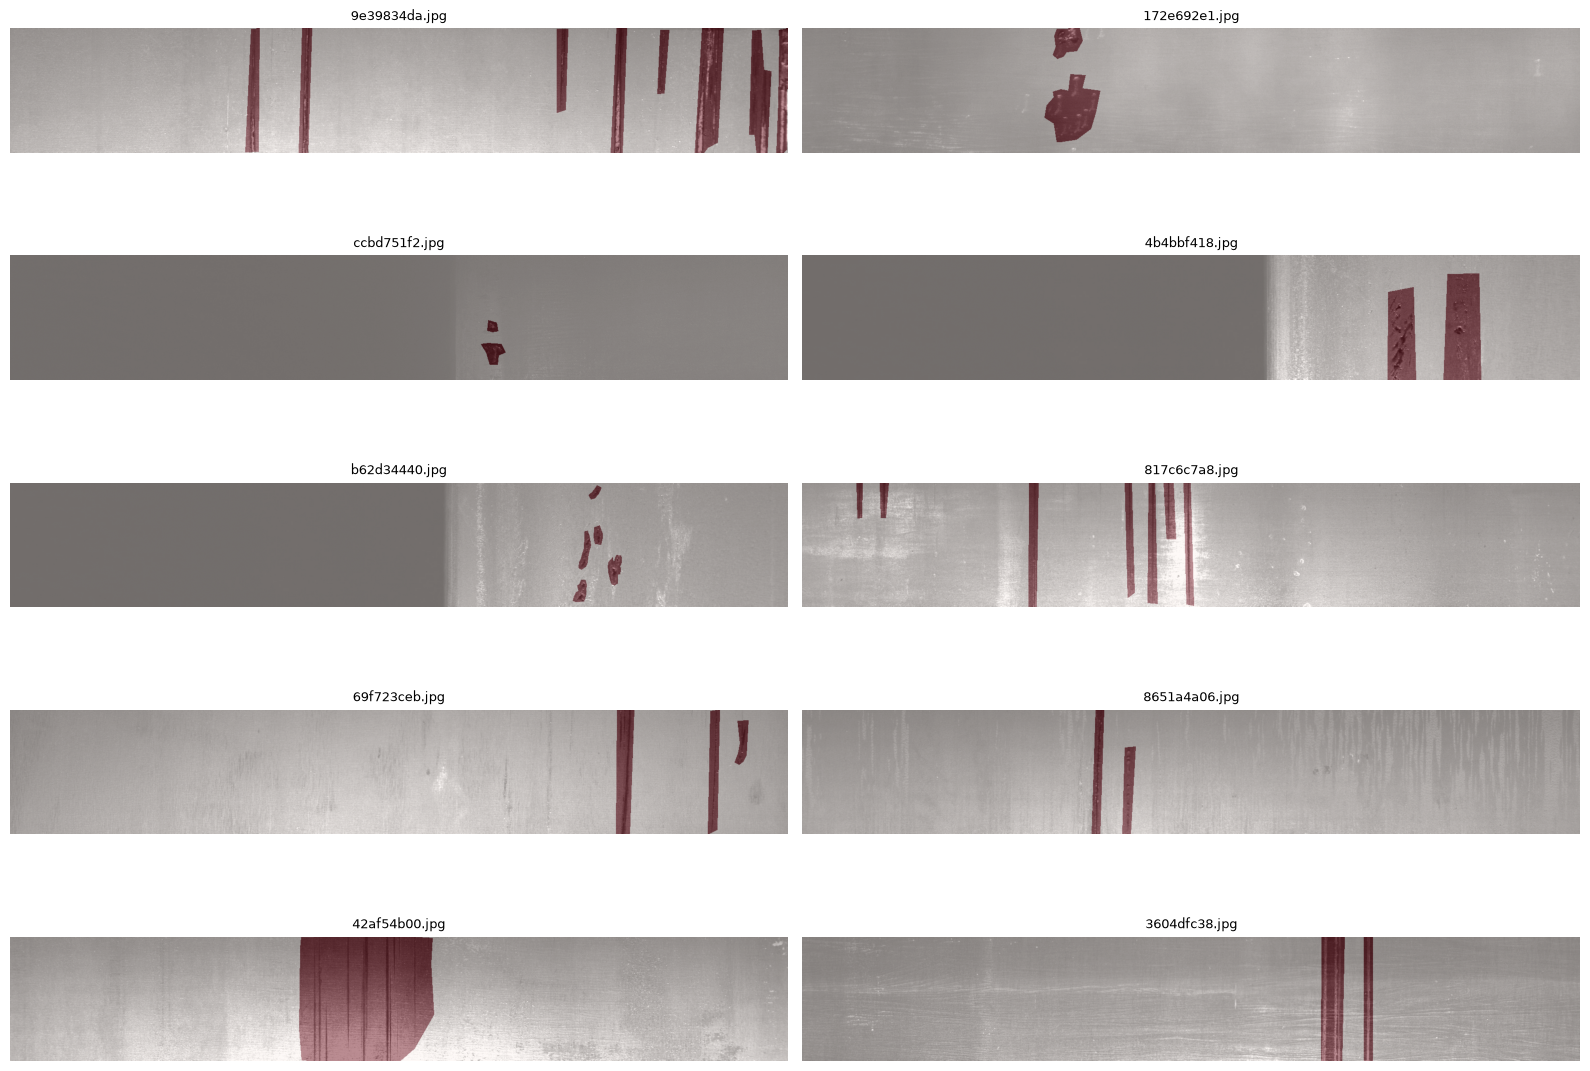

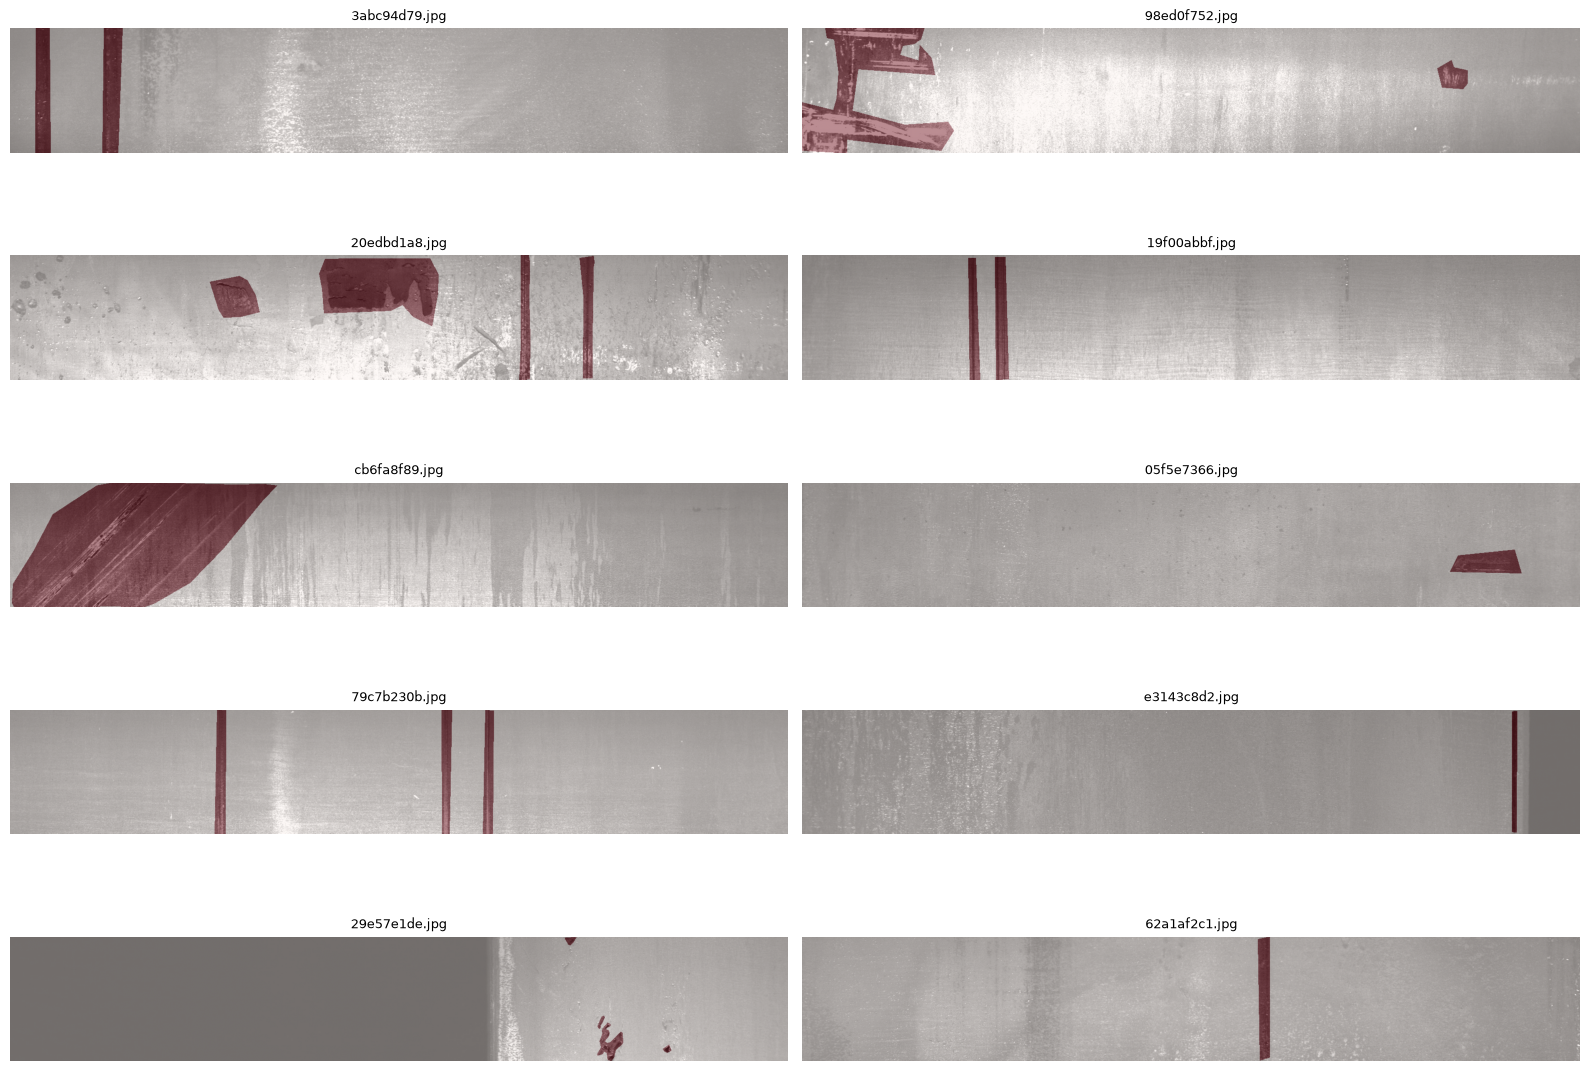

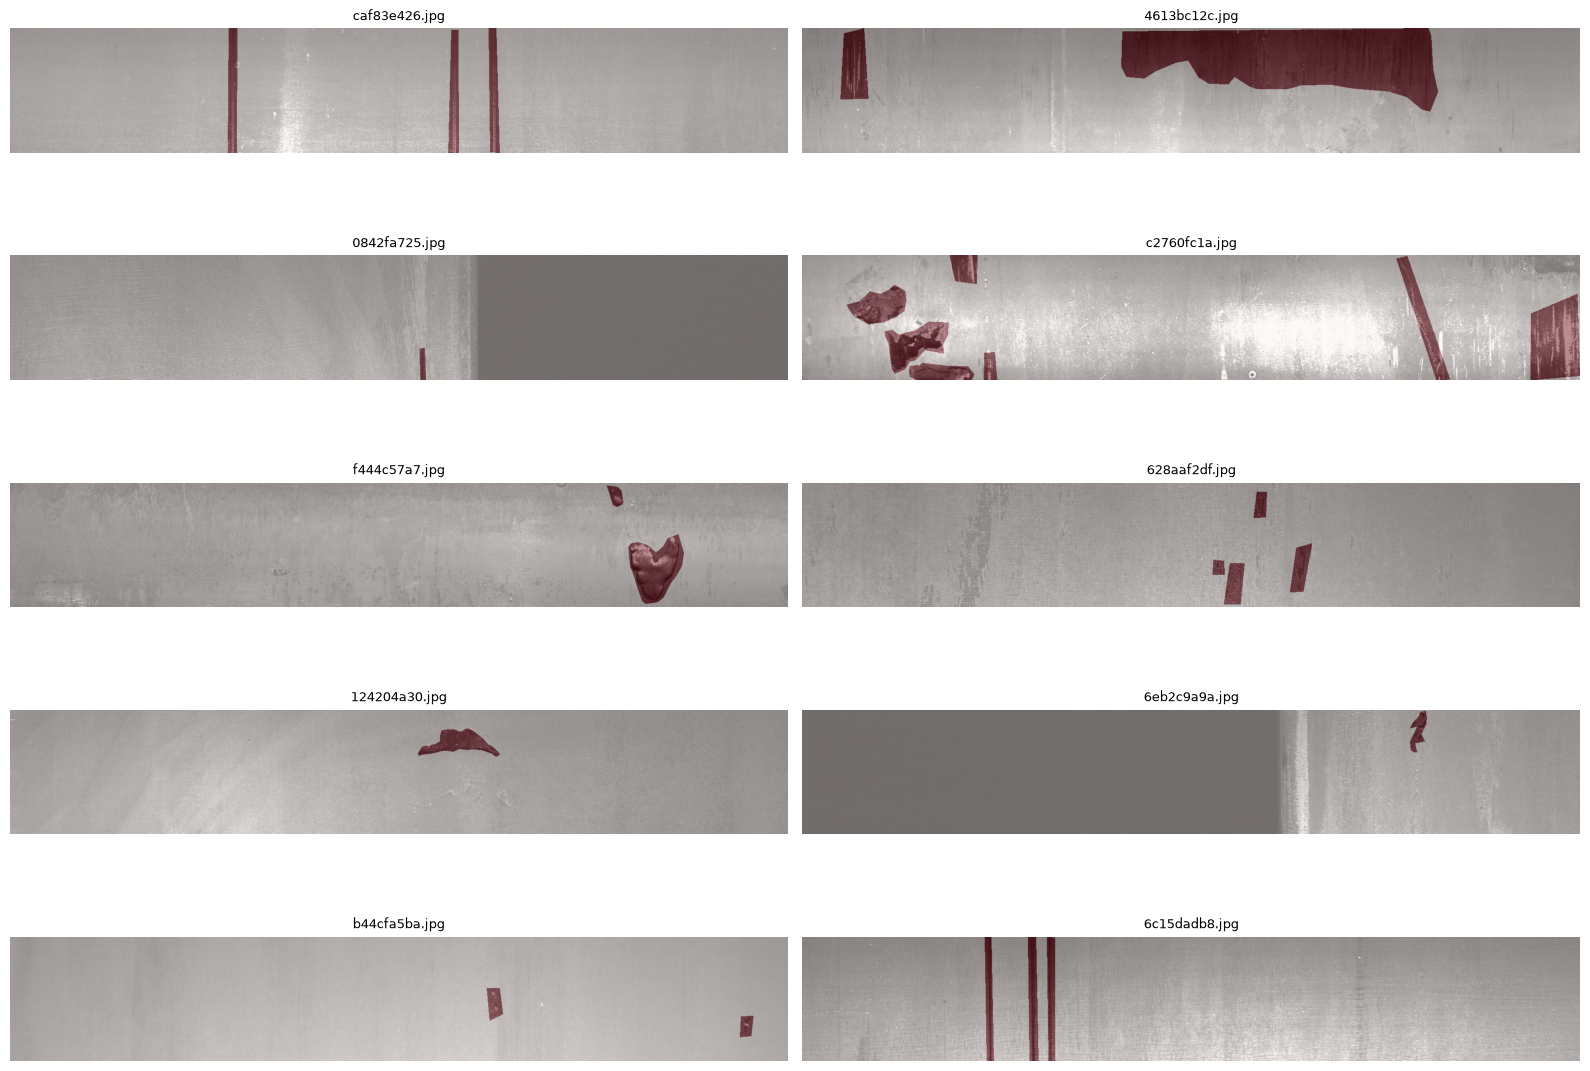

Overlay seed: 532
Unique images inspected: 30


In [36]:

import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

SEED_OVERLAY = 532
rng = np.random.default_rng(SEED_OVERLAY)

# Sample 30 unique annotated images.
annotated_ids = sorted(df["ImageId"].unique().tolist())
sample_ids = rng.choice(annotated_ids, size=30, replace=False).tolist()

def union_mask_for_image(image_id):
    mask = np.zeros((256, 1600), dtype=np.uint8)
    rows = df.loc[df["ImageId"] == image_id, "EncodedPixels"]
    for rle in rows:
        mask |= decode_rle_checked(rle)
    return mask

for batch_start in range(0, 30, 10):
    batch_ids = sample_ids[batch_start:batch_start + 10]
    fig, axes = plt.subplots(5, 2, figsize=(16, 12))

    for ax, image_id in zip(axes.flat, batch_ids):
        image_path = DATA_DIR / "train_images" / image_id

        with Image.open(image_path) as img:
            image = img.convert("RGB")

        mask = union_mask_for_image(image_id)

        ax.imshow(image)
        ax.imshow(mask, cmap="Reds", alpha=0.45, vmin=0, vmax=1)
        ax.set_title(image_id, fontsize=9)
        ax.axis("off")

    plt.tight_layout()
    plt.show()

print("Overlay seed:", SEED_OVERLAY)
print("Unique images inspected:", len(sample_ids))


In [37]:
import json
from pathlib import Path

overlay_audit = {
    "seed": 532,
    "sample_size": 30,
    "unique_annotated_images": len(sample_ids),
    "review_status": "completed_visual_spot_check",
    "observations": [
        "No obvious systematic mask displacement or rotation observed.",
        "Masks generally align with visible defect regions.",
        "Some large or irregular masks may warrant closer inspection.",
    ],
    "limitations": [
        "Qualitative visual inspection only.",
        "Does not establish pixel-perfect annotation correctness.",
    ],
}

audit_path = MANIFEST_DIR / "overlay_audit.json"

with open(audit_path, "w") as f:
    json.dump(overlay_audit, f, indent=2)

print("Saved:", audit_path)
print("Images reviewed:", len(sample_ids))
print("Status:", overlay_audit["review_status"])

Saved: E:\SAM\manifests\overlay_audit.json
Images reviewed: 30
Status: completed_visual_spot_check


In [38]:

import json
import hashlib
from pathlib import Path

manifest_path = MANIFEST_DIR / "split_manifest_v2.json"
proposal_path = MANIFEST_DIR / "proposed_training_exclusions.json"
pool_path = MANIFEST_DIR / "effective_train_pool_provisional.json"
overlay_path = MANIFEST_DIR / "overlay_audit.json"

with open(manifest_path) as f:
    manifest = json.load(f)
with open(proposal_path) as f:
    proposal = json.load(f)
with open(pool_path) as f:
    effective = json.load(f)
with open(overlay_path) as f:
    overlay = json.load(f)

splits = manifest["splits"]
test_E = set(splits["test_E"])
dev = set(splits["dev"])
pool = set(splits["train_pool"])
S1 = set(splits["S1"])
H = set(splits["H"])
excluded = set(proposal["proposed_training_exclusions"])
effective_pool = set(effective["effective_train_pool"])

checks = {
    "test_E size is 1200": len(test_E) == 1200,
    "dev size is 200": len(dev) == 200,
    "train_pool size is 11168": len(pool) == 11168,
    "S1 size is 50": len(S1) == 50,
    "H size is 10": len(H) == 10,
    "Primary splits disjoint": not (
        test_E & dev or test_E & pool or dev & pool
    ),
    "S1 contained in original pool": S1.issubset(pool),
    "H contained in test_E": H.issubset(test_E),
    "Exclusions contained in pool": excluded.issubset(pool),
    "Effective pool matches exclusions": effective_pool == pool - excluded,
    "Overlay audit reports 30 images": overlay["sample_size"] == 30,
}

for name, passed in checks.items():
    print(f"{'PASS' if passed else 'FAIL'}: {name}")

print("\nManifest SHA-256:",
      hashlib.sha256(manifest_path.read_bytes()).hexdigest())
print("Overall:", "PASS" if all(checks.values()) else "FAIL")
print("Note: near-duplicate review remains unresolved.")


PASS: test_E size is 1200
PASS: dev size is 200
PASS: train_pool size is 11168
PASS: S1 size is 50
PASS: H size is 10
PASS: Primary splits disjoint
PASS: S1 contained in original pool
PASS: H contained in test_E
PASS: Exclusions contained in pool
PASS: Effective pool matches exclusions
PASS: Overlay audit reports 30 images

Manifest SHA-256: 06819a37ed62823d0cc6972bfbc161fcfc2062b59bf630af8fd5121494f7b762
Overall: PASS
Note: near-duplicate review remains unresolved.
